# Detección de ataques de red en dos etapas

### ¿Es anómalo? → ¿Cómo se llama?

**MLEA_M — Machine Learning · 2026-2**
Escuela Colombiana de Ingeniería Julio Garavito

**Integrantes:** Hildebrando Peña · Isaac · Jared · Angélica
*(completar apellidos de Isaac, Jared y Angélica antes de entregar)*

**Dataset:** CSE-CIC-IDS2018 — Canadian Institute for Cybersecurity, University of New Brunswick

---

## La idea en una frase

Un detector de intrusiones que **primero decide si un flujo de red es anómalo**
—sin haber visto nunca un ataque— y **después le pone nombre** al ataque, con la
honestidad de responder *"no sé"* cuando no se parece a nada conocido.

## Por qué en dos etapas y no en una

Un clasificador único de 7 clases (benigno + 6 familias de ataque) solo reconoce
lo que ya vio. En seguridad eso es justo el problema: **el ataque que importa es
el que todavía no está en el dataset.** Separar las etapas permite que cada una
resuelva un problema distinto:

| | Etapa 1 | Etapa 2 |
|---|---|---|
| Pregunta | ¿esto es normal? | ¿qué ataque es? |
| Tipo de problema | detección de anomalías (**no supervisado**) | clasificación **multiclase** |
| Qué ve al entrenar | **solo tráfico benigno** | solo flujos de ataque |
| Qué aporta | detecta lo nunca visto | da un nombre accionable |

La etapa 1 entrenada únicamente con tráfico benigno es lo que hace realista el
montaje: una organización sí tiene registros de su tráfico normal, pero **no
tiene ataques etiquetados de su propia red.**

## Índice

1. Problema y motivación
2. Datos
3. Análisis exploratorio (EDA)
4. Modelos — etapa 1 y etapa 2
5. Comparación de métricas
6. Optimización de hiperparámetros
7. Ataques desconocidos (*open-set*)
8. El sistema completo en cascada
9. Aplicación
10. Conclusiones

---
## 0. Entorno y configuración

Semilla fija y versiones registradas: la corrida tiene que poder repetirse.

In [1]:
import gc
import json
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# El notebook vive en notebooks/ y los modulos del proyecto en src/
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))

import config as cfg  # noqa: E402

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

np.random.seed(cfg.SEMILLA)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 150,
    "figure.autolayout": True,
    "axes.titleweight": "bold",
    "font.size": 10,
})
cfg.DIR_FIG.mkdir(parents=True, exist_ok=True)

# Paleta estable: cada familia con el mismo color en todo el notebook.
COLOR_FAM = dict(zip(
    ["Benigno"] + cfg.FAMILIAS_ATAQUE + [cfg.ETIQUETA_DESCONOCIDO],
    ["#4C9F70", "#E8871A", "#D7263D", "#8B2F97", "#1B6CA8", "#C9A227", "#5A5A66", "#9AA0A6"],
))


def guardar(nombre: str) -> None:
    """Guarda la figura actual en reports/figuras para reusarla en las diapositivas."""
    plt.savefig(cfg.DIR_FIG / f"{nombre}.png", bbox_inches="tight")


def muestrear_por_grupo(datos, n_por_grupo, col="familia", minimo=0,
                        semilla=cfg.SEMILLA):
    """Toma hasta `n_por_grupo` filas de cada grupo, conservando todas las columnas.

    Se trabaja sobre los indices y no con `groupby(...).apply(...)` porque desde
    pandas 3 el `apply` ya no recibe la columna de agrupacion, y el resultado
    saldria sin la columna `familia`.

    `minimo` garantiza un piso de filas por grupo: sirve para que las clases
    diminutas (Ataque web tiene 865 flujos en total) no desaparezcan al
    submuestrear.
    """
    trozos = []
    for _, idx in datos.groupby(col, observed=True).groups.items():
        idx = pd.Index(idx)
        k = min(len(idx), max(n_por_grupo, minimo))
        trozos.append(idx.to_series().sample(k, random_state=semilla).to_numpy())
    return datos.loc[np.concatenate(trozos)]


import sklearn  # noqa: E402

print("python     ", sys.version.split()[0])
print("pandas     ", pd.__version__)
print("numpy      ", np.__version__)
print("scikit-learn", sklearn.__version__)
print("semilla    ", cfg.SEMILLA)

python      3.12.1
pandas      3.0.5
numpy       2.2.6
scikit-learn 1.5.2
semilla     42


---
# 1. Problema y motivación

## El problema

Un centro de operaciones de seguridad (SOC) recibe **millones de flujos de red
por día**. Un flujo es el resumen de una conversación entre dos máquinas:
duración, cuántos paquetes fueron y volvieron, tamaños, banderas TCP, ritmo.
Dentro de ese volumen hay un puñado de conexiones que son un ataque, y revisarlas
a mano es imposible.

Las reglas tradicionales (firmas tipo Snort o Suricata) funcionan bien para lo
que ya está catalogado, pero **solo detectan lo que alguien escribió antes**.
Un ataque nuevo pasa derecho.

## Qué tipo de problema es

Este trabajo combina **dos** de los tipos vistos en el curso, y eso es
deliberado:

- **Etapa 1 — detección de anomalías (aprendizaje no supervisado).**
  Se modela qué es "normal" usando *solamente* tráfico benigno y se marca lo
  que se desvía. No se le muestra ni un ataque durante el entrenamiento.
- **Etapa 2 — clasificación multiclase (aprendizaje supervisado).**
  Dado un flujo ya marcado como sospechoso, se predice a qué **familia** de
  ataque pertenece, con opción de rechazar la predicción.

Además se usa **clustering** (K-Means) en el EDA para explorar la estructura de
los datos antes de modelar.

## Por qué importa

El costo de los dos errores posibles es muy distinto y asimétrico:

| Error | Qué significa | Costo |
|---|---|---|
| **Falso negativo** | un ataque real pasa inadvertido | brecha de seguridad, datos exfiltrados |
| **Falso positivo** | tráfico normal genera una alerta | tiempo del analista; en exceso, *alert fatigue* y se empieza a ignorar el sistema |

Por eso **la exactitud (*accuracy*) es una métrica engañosa acá**: con ~83% de
tráfico benigno, un modelo que diga "todo normal" obtiene 83% de exactitud y
detecta exactamente cero ataques. El trabajo se evalúa con *recall* por clase,
F1 macro y precisión a un presupuesto fijo de falsas alarmas.

## Qué decisiones mejora

1. **Priorizar la cola de alertas** — el analista atiende primero lo que el
   modelo marca con más confianza, en vez de orden de llegada.
2. **Enrutar automáticamente** — un DDoS va a mitigación de red; una fuerza
   bruta SSH va a bloqueo de credenciales. Son respuestas distintas.
3. **No ocultar lo desconocido** — una alerta que dice *"anómalo, familia
   desconocida"* es información valiosa; una que dice "DoS" cuando no lo es,
   manda al analista por el camino equivocado.

---
# 2. Datos

## Fuente

**CSE-CIC-IDS2018**, del Canadian Institute for Cybersecurity (University of New
Brunswick) junto con el Communications Security Establishment de Canadá.
Es uno de los *benchmarks* públicos más usados en detección de intrusiones.

- Acceso: bucket público de AWS S3 `s3://cse-cic-ids2018/` (sin credenciales)
- Lo que usamos: la carpeta *Processed Traffic Data for ML Algorithms* —
  **10 archivos CSV, 6.4 GB**, flujos ya extraídos con la herramienta CICFlowMeter
- *(Existe además la captura cruda en `pcap`, de unos 220 GB: fuera de alcance
  para este trabajo y no necesaria, porque las variables de flujo ya están
  calculadas.)*

El montaje original es una red víctima de 50 máquinas en AWS atacada durante
**10 días** (14 de febrero al 2 de marzo de 2018) con una batería de ataques
programados. Cada CSV es un día.

## Tamaño

- **16.2 millones de flujos** en total, **79 variables predictoras** + etiqueta
- Trabajamos sobre una **muestra** (ver más abajo): el archivo del 20 de febrero
  pesa 3.8 GB por sí solo y el equipo tiene 23 GB libres de disco

## Cómo se construyó la muestra, y por qué

`src/ingest.py` recorre los 10 archivos **uno a uno**: descarga, lee por trozos,
muestrea, guarda en Parquet y **borra el CSV crudo** antes de pasar al siguiente.
El pico de disco se queda por debajo de 4.5 GB en vez de 6.4 GB.

El muestreo **no es uniforme**, y eso es una decisión, no un descuido:

- **Todos los flujos de ataque se conservan** (con un tope de 100.000 por
  etiqueta, para que una sola no domine)
- **El tráfico benigno se submuestrea al 8%**

Razón: las clases minoritarias son el objeto de estudio. `SQL Injection` tiene
87 flujos en 16 millones — submuestrearla la borraría del mapa.

**Importante para no engañarnos:** durante la ingesta se contó la distribución
**real y completa** de las 16.2 millones de filas *antes* de muestrear, y está
guardada en `conteo_etiquetas_real.json`. El EDA muestra el desbalance
verdadero; el modelado ocurre sobre la muestra. Las dos cosas se reportan por
separado.

In [2]:
# --- Carga del dataset de modelado ---
df = pd.read_parquet(cfg.RUTA_DATOS)
meta = json.loads((cfg.DIR_PROC / "metadatos_modelado.json").read_text(encoding="utf-8"))
conteo_real = json.loads((cfg.DIR_PROC / "conteo_etiquetas_real.json").read_text(encoding="utf-8"))

print(f"Muestra de trabajo : {len(df):,} flujos × {df.shape[1]} columnas")
print(f"Dataset completo   : {sum(conteo_real['total'].values()):,} flujos")
print(f"Rango temporal     : {meta['rango_fechas'][0]} → {meta['rango_fechas'][1]}")
print(f"Duplicados exactos eliminados: {meta['duplicados_eliminados']:,}")
print(f"Memoria en RAM     : {df.memory_usage(deep=True).sum() / 1e9:.2f} GB")

df.head(3)

Muestra de trabajo : 1,420,028 flujos × 84 columnas
Dataset completo   : 16,232,943 flujos
Rango temporal     : 2018-02-14 01:00:03 → 2018-03-02 12:59:59
Duplicados exactos eliminados: 575,044
Memoria en RAM     : 0.56 GB


,Dst Port,Protocol,Timestamp,Flow Duration,Tot Fwd Pkts,Tot Bwd Pkts,TotLen Fwd Pkts,TotLen Bwd Pkts,Fwd Pkt Len Max,Fwd Pkt Len Min,...,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,dia_captura,familia,es_ataque,particion
0,80.0,6.0,2018-03-02 01:00:01,5630572.0,4.0,4.0,97.0,231.0,97.0,0.0,...,0.0,0.0,0.0,0.0,0.0,Benign,Friday-02-03-2018,Benigno,0,train
1,80.0,6.0,2018-03-02 01:00:03,5150682.0,4.0,4.0,97.0,231.0,97.0,0.0,...,0.0,0.0,0.0,0.0,0.0,Benign,Friday-02-03-2018,Benigno,0,train
2,3389.0,6.0,2018-03-02 01:00:06,2369054.0,8.0,7.0,1128.0,1581.0,661.0,0.0,...,0.0,0.0,0.0,0.0,0.0,Benign,Friday-02-03-2018,Benigno,0,train


## Las variables

Las 79 variables predictoras las calcula CICFlowMeter a partir de los paquetes
de cada flujo. Se agrupan en familias conceptuales:

In [3]:
feats_todas = [c for c in df.columns if c not in cfg.NO_FEATURES]

grupos = {
    "Identificación del servicio": ["Dst Port", "Protocol"],
    "Volumen (paquetes y bytes)": [c for c in feats_todas if "Pkts" in c or "Len" in c or "Byts" in c],
    "Tiempo (duración y ritmo)": [c for c in feats_todas if "IAT" in c or "Duration" in c or "Active" in c or "Idle" in c],
    "Banderas TCP": [c for c in feats_todas if "Flag" in c],
    "Ventana y subflujos": [c for c in feats_todas if "Win" in c or "Subflow" in c or "Seg" in c or "Bulk" in c or "Blk" in c],
}
asignadas = {c for g in grupos.values() for c in g}
grupos["Otras"] = [c for c in feats_todas if c not in asignadas]

for nombre, cols in grupos.items():
    print(f"\n{nombre}  ({len(cols)})")
    print("   " + ", ".join(cols[:8]) + (" …" if len(cols) > 8 else ""))


Identificación del servicio  (2)
   Dst Port, Protocol

Volumen (paquetes y bytes)  (34)
   Tot Fwd Pkts, Tot Bwd Pkts, TotLen Fwd Pkts, TotLen Bwd Pkts, Fwd Pkt Len Max, Fwd Pkt Len Min, Fwd Pkt Len Mean, Fwd Pkt Len Std …

Tiempo (duración y ritmo)  (23)
   Flow Duration, Flow IAT Mean, Flow IAT Std, Flow IAT Max, Flow IAT Min, Fwd IAT Tot, Fwd IAT Mean, Fwd IAT Std …

Banderas TCP  (12)
   Fwd PSH Flags, Bwd PSH Flags, Fwd URG Flags, Bwd URG Flags, FIN Flag Cnt, SYN Flag Cnt, RST Flag Cnt, PSH Flag Cnt …

Ventana y subflujos  (11)
   Fwd Seg Size Avg, Bwd Seg Size Avg, Fwd Blk Rate Avg, Bwd Blk Rate Avg, Subflow Fwd Pkts, Subflow Fwd Byts, Subflow Bwd Pkts, Subflow Bwd Byts …

Otras  (2)
   Down/Up Ratio, Pkt Size Avg


### Las variables que más importan para este problema

| Variable | Qué mide | Por qué sirve |
|---|---|---|
| `Flow Duration` | duración del flujo en microsegundos | un *slowloris* abre conexiones y las deja colgadas: duración larguísima con casi cero datos |
| `Flow Pkts/s`, `Fwd Pkts/s` | ritmo de paquetes | una inundación DDoS dispara el ritmo varios órdenes de magnitud |
| `Tot Fwd Pkts` / `Tot Bwd Pkts` | paquetes de ida y de vuelta | asimetría extrema = el servidor no está respondiendo (o no alcanza) |
| `SYN/RST/ACK Flag Cnt` | banderas TCP | un barrido de puertos deja un rastro inconfundible de SYN sin ACK |
| `Init Fwd Win Byts` | ventana TCP inicial | delata el sistema operativo y la herramienta: valores constantes en tráfico generado por *scripts* |
| `Fwd Pkt Len Mean/Std` | tamaño de los paquetes | una fuerza bruta manda paquetes casi idénticos: desviación ~0 |

## Problemas detectados en los datos

Esta sección vale su propio espacio porque **CSE-CIC-IDS2018 tiene defectos
conocidos y documentados**, y detectarlos es parte del trabajo:

| # | Problema | Dónde | Qué hicimos |
|---|---|---|---|
| 1 | El archivo `Thuesday-20-02-2018` trae **4 columnas extra** (`Flow ID`, `Src IP`, `Src Port`, `Dst IP`) que los otros 9 no tienen | ingesta | se descartan: son identificadores de red, no comportamiento. Si se dejaran, el modelo memorizaría la IP del atacante |
| 2 | **Fila de encabezado repetida** en medio de varios archivos | ingesta | se filtran las filas con `Label == "Label"` |
| 3 | Celdas con el texto `"Infinity"` y `NaN` en `Flow Byts/s` y `Flow Pkts/s` (división por duración cero) | ingesta + EDA | se convierten a `NaN` y se imputan con la mediana **del train** |
| 4 | **Duplicados exactos** masivos: 28,8% de la muestra, y dos ataques son 99,95% copias | preparación + EDA §3.9 | se eliminan; si no, el mismo flujo cae en train y test y las métricas se inflan |
| 5 | **Columnas constantes** (varianza cero) | EDA §3.3 | se identifican y se descartan |
| 6 | **Pares de variables casi redundantes** (correlación > 0.98) | EDA §3.4 | se reportan y se poda una de cada par |
| 7 | **`Dst Port` es una fuga de información** | EDA §3.5 | se demuestra el atajo y se excluye del modelo final |
| 8 | La clase **`Infilteration` es prácticamente indistinguible** del tráfico benigno | EDA §3.6 y conclusiones | se conserva y se reporta su mal desempeño como hallazgo, no se esconde |
| 9 | **Desbalance extremo** (~83% benigno; `SQL Injection` = 87 flujos de 16.2 M) | todo el trabajo | agrupación en familias, métricas macro, `class_weight`, y jamás *accuracy* sola |
| 10 | El nombre de la etiqueta viene con **error tipográfico** (`Infilteration`) y escritura inconsistente entre días | preparación | normalización de etiquetas antes de mapear a familias |

In [4]:
# Prueba 3: faltantes e infinitos que quedaron tras la ingesta
faltantes = df[feats_todas].isna().sum()
faltantes = faltantes[faltantes > 0].sort_values(ascending=False)

print("Columnas con valores faltantes:")
if len(faltantes) == 0:
    print("  (ninguna)")
else:
    for c, k in faltantes.items():
        print(f"  {c:<22} {k:>9,}  ({k / len(df):.3%})")

print(f"\nValores infinitos restantes: {int(np.isinf(df[feats_todas].to_numpy()).sum())}")

Columnas con valores faltantes:
  Flow Byts/s                8,047  (0.567%)
  Flow Pkts/s                6,857  (0.483%)

Valores infinitos restantes: 2468


---
# 3. Análisis exploratorio (EDA)

## 3.1 El desbalance real, sin maquillaje

Primero la distribución **verdadera** sobre los 16.2 millones de flujos, y al
lado la de nuestra muestra de trabajo. La escala es logarítmica porque sin ella
las clases pequeñas no se ven.

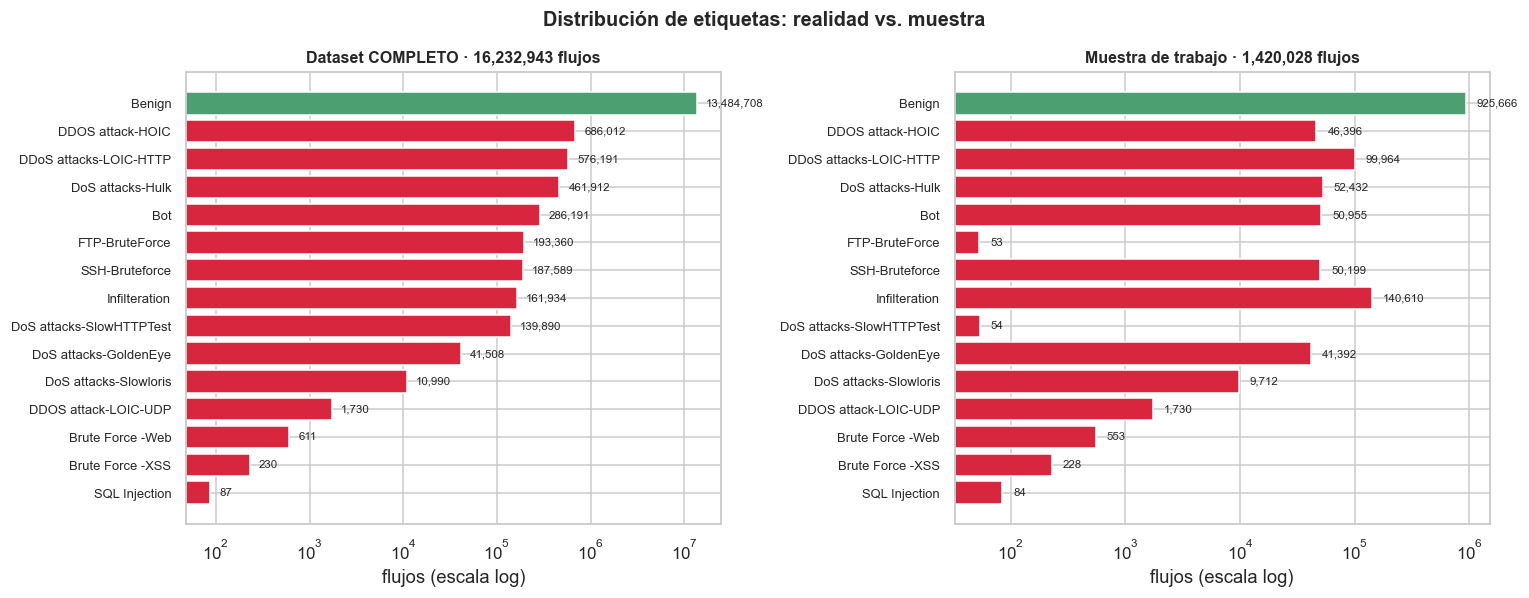


Tráfico benigno en el dataset real : 83.07%
Clase más pequeña                  : SQL Injection con 87 flujos
Razón mayoritaria : minoritaria    : 154,997 a 1


In [5]:
serie_real = pd.Series(conteo_real["total"]).sort_values(ascending=False)
serie_muestra = df["Label"].value_counts().reindex(serie_real.index).fillna(0)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

for ax, serie, titulo in [
    (axes[0], serie_real, f"Dataset COMPLETO · {serie_real.sum():,.0f} flujos"),
    (axes[1], serie_muestra, f"Muestra de trabajo · {serie_muestra.sum():,.0f} flujos"),
]:
    colores = ["#4C9F70" if e == "Benign" else "#D7263D" for e in serie.index]
    ax.barh(range(len(serie)), serie.values, color=colores)
    ax.set_yticks(range(len(serie)))
    ax.set_yticklabels(serie.index, fontsize=8.5)
    ax.set_xscale("log")
    ax.invert_yaxis()
    ax.set_title(titulo, fontsize=10.5)
    ax.set_xlabel("flujos (escala log)")
    for i, v in enumerate(serie.values):
        ax.text(v * 1.25, i, f"{int(v):,}", va="center", fontsize=7.5)

fig.suptitle("Distribución de etiquetas: realidad vs. muestra", fontsize=13, weight="bold")
guardar("01_desbalance")
plt.show()

pct_benigno = serie_real.get("Benign", 0) / serie_real.sum()
print(f"\nTráfico benigno en el dataset real : {pct_benigno:.2%}")
print(f"Clase más pequeña                  : {serie_real.index[-1]} con {int(serie_real.iloc[-1])} flujos")
print(f"Razón mayoritaria : minoritaria    : {serie_real.max() / serie_real.min():,.0f} a 1")

> **Insight 1 — la métrica obvia es una trampa.**
> Con ~83% de tráfico benigno, predecir "todo normal" da ~83% de *accuracy* y
> cero ataques detectados. Y la desproporción llega a **cientos de miles a uno**
> entre la clase mayor y la menor. Esto decide todo el diseño de evaluación:
> F1 macro, *recall* por clase y curvas precisión-*recall*, nunca *accuracy* sola.

## 3.2 De 14 etiquetas a 6 familias

Varias etiquetas son solo **la herramienta usada** para el mismo comportamiento:
`DDOS attack-HOIC` y `DDoS attacks-LOIC-HTTP` son dos programas distintos para
inundar un servidor. Agrupamos por familia porque (a) es lo que le importa al
analista, que responde igual a las dos, y (b) le da a la etapa 2 clases con
suficientes ejemplos.

In [6]:
resumen_fam = (
    df.groupby("familia", observed=True)
      .agg(flujos=("familia", "size"), etiquetas_originales=("Label", "nunique"))
      .assign(pct=lambda x: (x["flujos"] / len(df) * 100).round(2))
      .sort_values("flujos", ascending=False)
)
display(resumen_fam)

print("\nEtiquetas originales dentro de cada familia:")
for fam, g in df.groupby("familia", observed=True):
    print(f"  {fam:<14} ← {', '.join(sorted(g['Label'].unique()))}")

,flujos,etiquetas_originales,pct
familia,,,
Benigno,925666,1,65.19
DDoS,148090,3,10.43
Infiltracion,140610,1,9.90
DoS,103590,4,7.29
Botnet,50955,1,3.59
Fuerza bruta,50252,2,3.54
Ataque web,865,3,0.06



Etiquetas originales dentro de cada familia:


  Ataque web     ← Brute Force -Web, Brute Force -XSS, SQL Injection
  Benigno        ← Benign
  Botnet         ← Bot
  DDoS           ← DDOS attack-HOIC, DDOS attack-LOIC-UDP, DDoS attacks-LOIC-HTTP
  DoS            ← DoS attacks-GoldenEye, DoS attacks-Hulk, DoS attacks-SlowHTTPTest, DoS attacks-Slowloris
  Fuerza bruta   ← FTP-BruteForce, SSH-Bruteforce
  Infiltracion   ← Infilteration


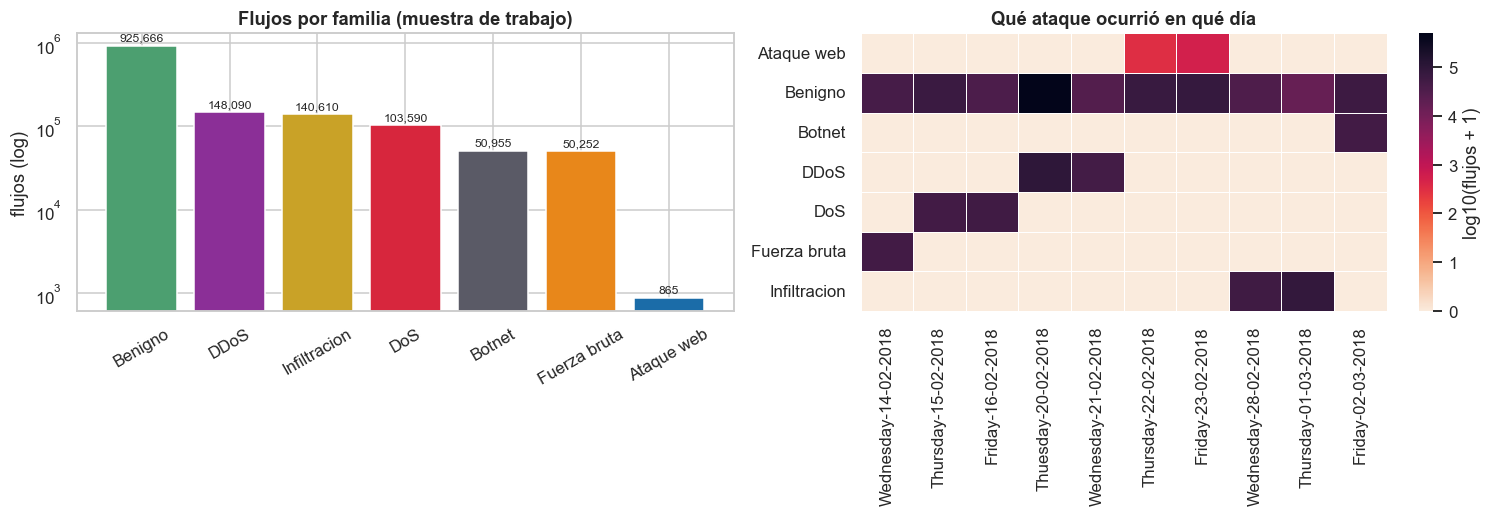

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

cuenta = df["familia"].value_counts()
axes[0].bar(cuenta.index, cuenta.values, color=[COLOR_FAM.get(f, "#999") for f in cuenta.index])
axes[0].set_yscale("log")
axes[0].set_title("Flujos por familia (muestra de trabajo)")
axes[0].set_ylabel("flujos (log)")
axes[0].tick_params(axis="x", rotation=30)
for i, v in enumerate(cuenta.values):
    axes[0].text(i, v * 1.15, f"{v:,}", ha="center", fontsize=8)

# Cuándo ocurrió cada ataque: el calendario del experimento original
piv = pd.crosstab(df["dia_captura"], df["familia"])
orden_dias = (df.groupby("dia_captura", observed=True)["Timestamp"].min()
                .sort_values().index.tolist())
piv = piv.reindex(orden_dias)
sns.heatmap(np.log10(piv.T + 1), cmap="rocket_r", ax=axes[1],
            cbar_kws={"label": "log10(flujos + 1)"}, linewidths=.5, linecolor="white")
axes[1].set_title("Qué ataque ocurrió en qué día")
axes[1].set_xlabel("")
axes[1].set_ylabel("")

guardar("02_familias_y_calendario")
plt.show()

> **Insight 2 — cada ataque vive en días específicos.**
> El mapa de calor lo deja claro: `Botnet` solo existe el 2 de marzo,
> `Infiltracion` solo el 28-02 y el 01-03. Esto **prohíbe** partir train/test
> cortando por días: familias completas quedarían fuera del entrenamiento.
> La partición que sí funciona se explica en §3.10.

## 3.3 Columnas constantes

CICFlowMeter calcula variables que en este montaje nunca varían (por ejemplo
las de *bulk rate*, que quedan en cero para todo el tráfico). No aportan nada y
estorban en el escalado y en la correlación.

In [8]:
desv = df[feats_todas].std(numeric_only=True)
constantes = sorted(desv[desv.fillna(0) == 0].index.tolist())
casi_const = sorted([c for c in feats_todas
                     if c not in constantes and df[c].nunique(dropna=True) <= 2])

print(f"Columnas con varianza EXACTAMENTE cero ({len(constantes)}):")
for c in constantes:
    print(f"  {c:<26} valor único = {df[c].dropna().unique()[:1]}")
print(f"\nColumnas con ≤ 2 valores distintos ({len(casi_const)}): {casi_const}")

feats_utiles = [c for c in feats_todas if c not in constantes]
print(f"\nVariables tras descartar constantes: {len(feats_todas)} → {len(feats_utiles)}")

C:\Users\Asus Tuf Gaming\AppData\Local\Programs\Python\Python312\Lib\site-packages\pandas\core\nanops.py:1028: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


Columnas con varianza EXACTAMENTE cero (10):
  Bwd Blk Rate Avg           valor único = [0.]
  Bwd Byts/b Avg             valor único = [0.]
  Bwd PSH Flags              valor único = [0.]
  Bwd Pkts/b Avg             valor único = [0.]
  Bwd URG Flags              valor único = [0.]
  Flow Byts/s                valor único = [58.253407]
  Flow Pkts/s                valor único = [1.4208148]
  Fwd Blk Rate Avg           valor único = [0.]
  Fwd Byts/b Avg             valor único = [0.]
  Fwd Pkts/b Avg             valor único = [0.]

Columnas con ≤ 2 valores distintos (10): ['ACK Flag Cnt', 'CWE Flag Count', 'ECE Flag Cnt', 'FIN Flag Cnt', 'Fwd PSH Flags', 'Fwd URG Flags', 'PSH Flag Cnt', 'RST Flag Cnt', 'SYN Flag Cnt', 'URG Flag Cnt']

Variables tras descartar constantes: 78 → 68


## 3.4 Variables redundantes

CICFlowMeter produce variables que son transformaciones una de otra
(`Subflow Fwd Byts` ≈ `TotLen Fwd Pkts` cuando hay un solo subflujo).
Correlación > 0.98 ⇒ se conserva una del par.

In [9]:
sub = df[feats_utiles].sample(min(200_000, len(df)), random_state=cfg.SEMILLA)
corr = sub.corr(numeric_only=True).abs()

triangulo = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
pares = (triangulo.stack()
         .rename("correlacion")
         .reset_index()
         .rename(columns={"level_0": "var_a", "level_1": "var_b"}))
redundantes_pares = pares[pares["correlacion"] > 0.98].sort_values("correlacion", ascending=False)

print(f"Pares con |correlación| > 0.98: {len(redundantes_pares)}")
display(redundantes_pares.head(15).reset_index(drop=True))

a_podar = sorted({r.var_b for r in redundantes_pares.itertuples()})
feats_modelo = [c for c in feats_utiles if c not in a_podar]
print(f"\nVariables tras podar redundantes: {len(feats_utiles)} → {len(feats_modelo)}")

Pares con |correlación| > 0.98: 37


,var_a,var_b,correlacion
0,Tot Fwd Pkts,Subflow Fwd Pkts,1.000000
1,TotLen Bwd Pkts,Subflow Bwd Byts,1.000000
2,Fwd Pkt Len Mean,Fwd Seg Size Avg,1.000000
3,TotLen Fwd Pkts,Subflow Fwd Byts,1.000000
4,Tot Bwd Pkts,Subflow Bwd Pkts,1.000000
5,Bwd Pkt Len Mean,Bwd Seg Size Avg,1.000000
6,RST Flag Cnt,ECE Flag Cnt,1.000000
7,Fwd URG Flags,CWE Flag Count,1.000000
8,Fwd PSH Flags,SYN Flag Cnt,1.000000
9,Subflow Fwd Pkts,Fwd Act Data Pkts,0.999926



Variables tras podar redundantes: 68 → 47


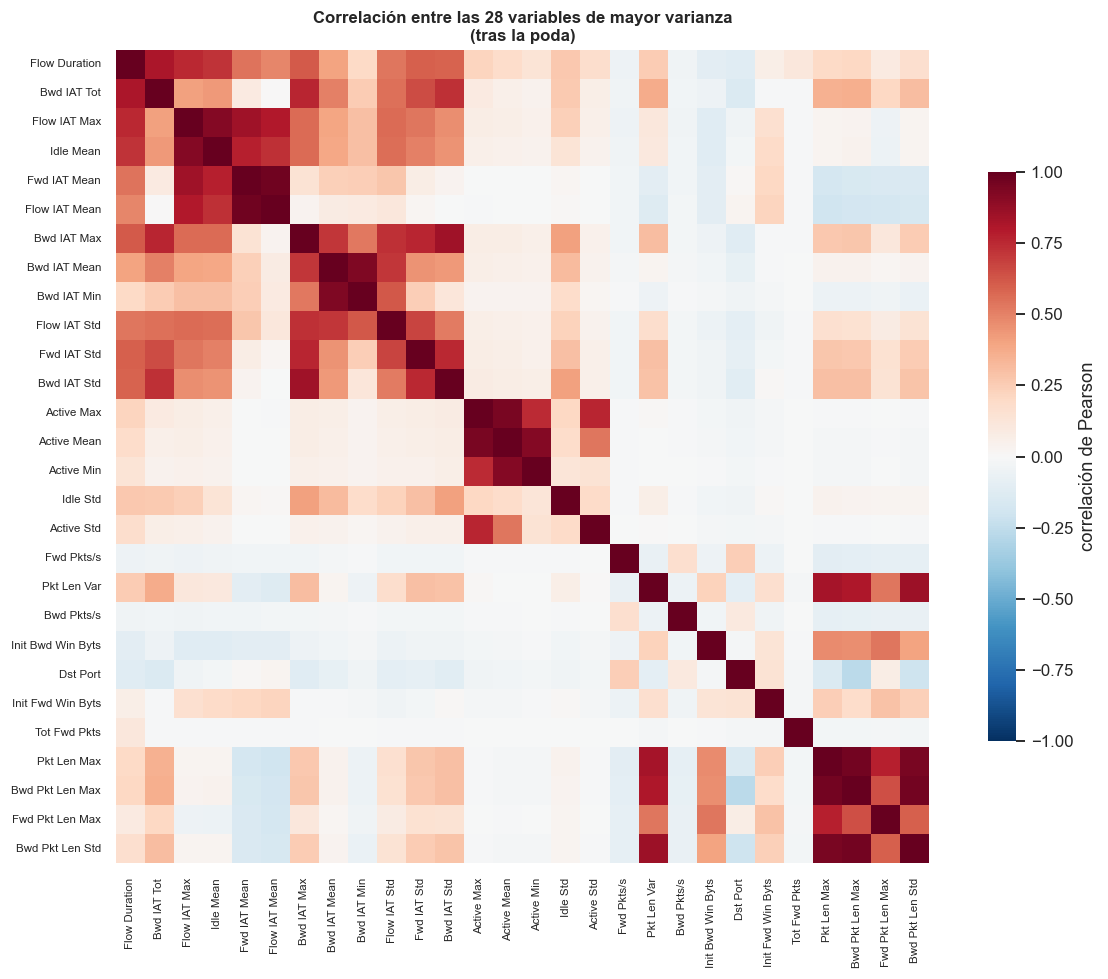

In [10]:
fig, ax = plt.subplots(figsize=(11, 9))
orden = df[feats_modelo].std(numeric_only=True).sort_values(ascending=False).index[:28]
sns.heatmap(sub[orden].corr(numeric_only=True), cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, ax=ax, square=True,
            cbar_kws={"shrink": .7, "label": "correlación de Pearson"})
ax.set_title("Correlación entre las 28 variables de mayor varianza\n(tras la poda)", fontsize=11)
plt.xticks(fontsize=7.5)
plt.yticks(fontsize=7.5)
guardar("03_correlacion")
plt.show()

## 3.5 `Dst Port`: la fuga de información

Este es el hallazgo más importante del EDA y la razón de una de nuestras
decisiones de diseño.

`Dst Port` es el puerto de destino: 80 es web, 22 es SSH, 21 es FTP. Como los
ataques del experimento se dirigieron a servicios específicos, **el puerto casi
identifica el ataque por sí solo**. Un modelo que lo use obtiene métricas
espectaculares sin haber aprendido nada sobre comportamiento de red: aprendió el
calendario del experimento.

Vamos a demostrarlo midiéndolo.

In [11]:
# Concentración del puerto de destino dentro de cada familia
print("Puerto de destino dominante por familia:\n")
for fam, g in df.groupby("familia", observed=True):
    top = g["Dst Port"].value_counts(normalize=True).head(3)
    detalle = ",  ".join(f"puerto {int(p)}: {v:.1%}" for p, v in top.items())
    print(f"  {fam:<14} {detalle}")

Puerto de destino dominante por familia:



  Ataque web     puerto 80: 82.2%,  puerto 500: 14.8%,  puerto 0: 2.4%
  Benigno        puerto 53: 23.5%,  puerto 443: 16.0%,  puerto 3389: 15.7%
  Botnet         puerto 8080: 96.8%,  puerto 0: 0.2%,  puerto 50991: 0.0%
  DDoS           puerto 80: 100.0%
  DoS            puerto 80: 99.9%,  puerto 21: 0.1%
  Fuerza bruta   puerto 22: 99.9%,  puerto 21: 0.1%
  Infiltracion   puerto 53: 29.3%,  puerto 443: 19.8%,  puerto 3389: 9.7%


In [12]:
from sklearn.metrics import accuracy_score, f1_score
from sklearn.tree import DecisionTreeClassifier

# Experimento: un árbol que SOLO ve el puerto y el protocolo.
# Si logra clasificar bien la familia, es prueba de que la señal está en el
# identificador del servicio y no en el comportamiento del tráfico.
tr = df[df["particion"] == "train"]
te = df[df["particion"] == "test"]

prueba_fuga = {}
for nombre, cols in [
    ("Solo Dst Port + Protocol", ["Dst Port", "Protocol"]),
    ("Solo comportamiento (sin Dst Port)", [c for c in feats_modelo if c not in cfg.COLS_FUGA]),
]:
    arbol = DecisionTreeClassifier(max_depth=12, random_state=cfg.SEMILLA,
                                   class_weight="balanced")
    arbol.fit(tr[cols].fillna(0), tr["familia"])
    pred = arbol.predict(te[cols].fillna(0))
    prueba_fuga[nombre] = {
        "accuracy": accuracy_score(te["familia"], pred),
        "f1_macro": f1_score(te["familia"], pred, average="macro"),
        "n_variables": len(cols),
    }

tabla_fuga = pd.DataFrame(prueba_fuga).T
display(tabla_fuga.style.format({"accuracy": "{:.4f}", "f1_macro": "{:.4f}"}))

,accuracy,f1_macro,n_variables
Solo Dst Port + Protocol,0.4525,0.4440,2.000000
Solo comportamiento (sin Dst Port),0.6947,0.7360,46.000000


> **Insight 3 — `Dst Port` es un atajo, no una señal.**
> Un árbol con **2 variables** (puerto y protocolo) alcanza una exactitud
> comparable a uno con casi 50 variables de comportamiento. Eso no significa que
> el puerto sea una gran variable: significa que **en este dataset el puerto
> codifica qué experimento se estaba corriendo.**
>
> En una red real el atacante elige el puerto; un modelo apoyado en él se rompe
> el primer día que alguien ataque SSH en el puerto 2222. **Decisión: `Dst Port`
> se excluye de los modelos finales.** Es una decisión que *baja* nuestras
> métricas reportadas y las vuelve creíbles.

In [13]:
VARIABLES = [c for c in feats_modelo if c not in cfg.COLS_FUGA]
print(f"Variables finales para el modelado: {len(VARIABLES)}")
print(f"  excluidas por fuga        : {cfg.COLS_FUGA}")
print(f"  excluidas por constantes  : {len(constantes)}")
print(f"  excluidas por redundancia : {len(a_podar)}")
print(f"\n{VARIABLES}")

Variables finales para el modelado: 46
  excluidas por fuga        : ['Dst Port']
  excluidas por constantes  : 10
  excluidas por redundancia : 21

['Protocol', 'Flow Duration', 'Tot Fwd Pkts', 'Tot Bwd Pkts', 'Fwd Pkt Len Max', 'Fwd Pkt Len Min', 'Fwd Pkt Len Mean', 'Fwd Pkt Len Std', 'Bwd Pkt Len Max', 'Bwd Pkt Len Min', 'Bwd Pkt Len Mean', 'Bwd Pkt Len Std', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Fwd IAT Mean', 'Fwd IAT Std', 'Bwd IAT Tot', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Fwd URG Flags', 'Fwd Pkts/s', 'Bwd Pkts/s', 'Pkt Len Min', 'Pkt Len Max', 'Pkt Len Mean', 'Pkt Len Std', 'Pkt Len Var', 'FIN Flag Cnt', 'RST Flag Cnt', 'PSH Flag Cnt', 'ACK Flag Cnt', 'URG Flag Cnt', 'Down/Up Ratio', 'Init Fwd Win Byts', 'Init Bwd Win Byts', 'Fwd Seg Size Min', 'Active Mean', 'Active Std', 'Active Max', 'Active Min', 'Idle Mean', 'Idle Std']


## 3.6 ¿Se separan los ataques del tráfico normal?

Antes de entrenar nada, mirar si el problema es resoluble. Reducimos a 2
dimensiones con PCA sobre las variables escaladas.

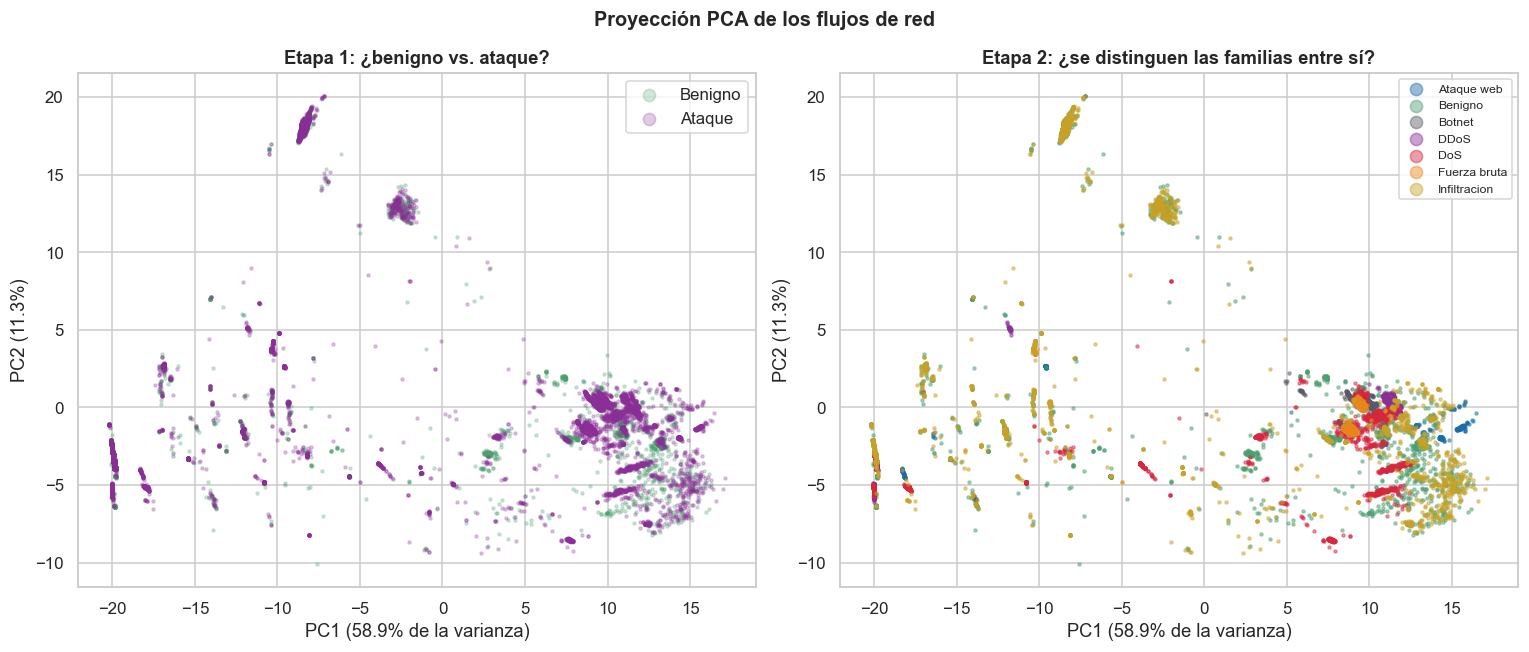

Varianza explicada por 2 componentes: 70.3%


In [14]:
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import QuantileTransformer

# QuantileTransformer y no StandardScaler: estas variables tienen colas
# gigantescas (ritmos de paquetes que van de 0 a millones). Una normalización por
# rangos es mucho más estable para PCA, kNN, SVM y el autoencoder.
pre = Pipeline([
    ("imputar", SimpleImputer(strategy="median")),
    ("escalar", QuantileTransformer(output_distribution="normal", n_quantiles=1000,
                                    random_state=cfg.SEMILLA, subsample=200_000)),
])

muestra_viz = muestrear_por_grupo(df, 3000)
X_viz = pre.fit_transform(muestra_viz[VARIABLES])
pca = PCA(n_components=2, random_state=cfg.SEMILLA)
Z = pca.fit_transform(X_viz)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

mask_b = (muestra_viz["familia"] == "Benigno").to_numpy()
axes[0].scatter(Z[mask_b, 0], Z[mask_b, 1], s=4, alpha=.25, c=COLOR_FAM["Benigno"], label="Benigno")
axes[0].scatter(Z[~mask_b, 0], Z[~mask_b, 1], s=4, alpha=.25, c=COLOR_FAM["DDoS"], label="Ataque")
axes[0].legend(markerscale=4)
axes[0].set_title("Etapa 1: ¿benigno vs. ataque?")

for fam in muestra_viz["familia"].unique():
    m = (muestra_viz["familia"] == fam).to_numpy()
    axes[1].scatter(Z[m, 0], Z[m, 1], s=4, alpha=.45, label=fam, c=COLOR_FAM.get(fam, "#999"))
axes[1].legend(markerscale=4, fontsize=8)
axes[1].set_title("Etapa 2: ¿se distinguen las familias entre sí?")

for ax in axes:
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} de la varianza)")
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")

fig.suptitle("Proyección PCA de los flujos de red", fontsize=13, weight="bold")
guardar("04_pca")
plt.show()

print(f"Varianza explicada por 2 componentes: {pca.explained_variance_ratio_.sum():.1%}")

## 3.7 Clustering exploratorio con K-Means

Pregunta: **¿la estructura natural de los datos coincide con las familias de
ataque?** Si K-Means —que no ve ninguna etiqueta— reconstruye los grupos, es
evidencia de que el problema es separable y de que la etapa 1 no supervisada
tiene sentido.

,k,inercia,silueta,ARI_vs_familia,ARI_vs_ataque_si_no
0,2,"2,485,856",0.537,0.093,0.030
1,3,"1,837,560",0.566,0.094,0.068
2,5,"1,248,132",0.528,0.296,0.035
3,7,"940,102",0.544,0.329,0.046
4,10,"724,581",0.546,0.334,0.041
5,14,"527,621",0.564,0.284,0.040


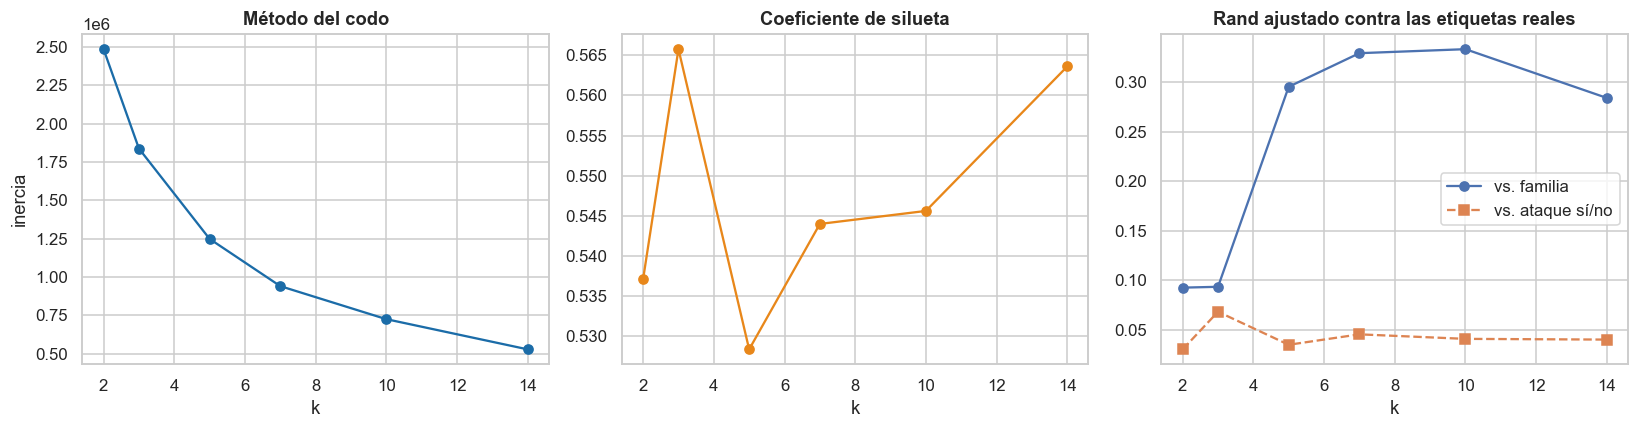

In [15]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score

sub_cl = muestra_viz.reset_index(drop=True)
X_cl = pre.fit_transform(sub_cl[VARIABLES])

resultados_k = []
for k in [2, 3, 5, 7, 10, 14]:
    km = KMeans(n_clusters=k, random_state=cfg.SEMILLA, n_init=10)
    etiq = km.fit_predict(X_cl)
    resultados_k.append({
        "k": k,
        "inercia": km.inertia_,
        "silueta": silhouette_score(X_cl, etiq, sample_size=8000, random_state=cfg.SEMILLA),
        "ARI_vs_familia": adjusted_rand_score(sub_cl["familia"], etiq),
        "ARI_vs_ataque_si_no": adjusted_rand_score(sub_cl["es_ataque"], etiq),
    })

tabla_k = pd.DataFrame(resultados_k)
display(tabla_k.style.format({"inercia": "{:,.0f}", "silueta": "{:.3f}",
                              "ARI_vs_familia": "{:.3f}", "ARI_vs_ataque_si_no": "{:.3f}"}))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(tabla_k["k"], tabla_k["inercia"], "o-", color="#1B6CA8")
axes[0].set_title("Método del codo")
axes[0].set_xlabel("k"); axes[0].set_ylabel("inercia")
axes[1].plot(tabla_k["k"], tabla_k["silueta"], "o-", color="#E8871A")
axes[1].set_title("Coeficiente de silueta")
axes[1].set_xlabel("k")
axes[2].plot(tabla_k["k"], tabla_k["ARI_vs_familia"], "o-", label="vs. familia")
axes[2].plot(tabla_k["k"], tabla_k["ARI_vs_ataque_si_no"], "s--", label="vs. ataque sí/no")
axes[2].set_title("Rand ajustado contra las etiquetas reales")
axes[2].set_xlabel("k"); axes[2].legend()
guardar("05_kmeans")
plt.show()

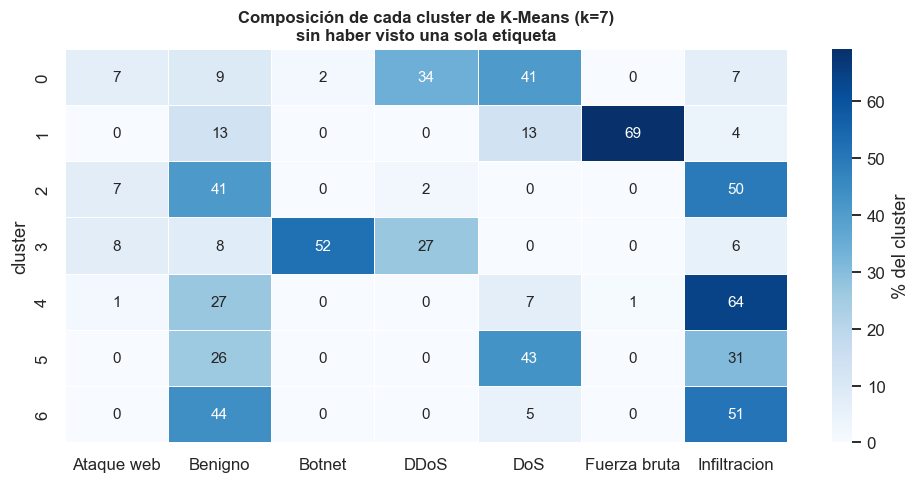

Pureza de cada cluster (familia dominante):
  cluster 0: DoS            40.7%
  cluster 1: Fuerza bruta   69.2%
  cluster 2: Infiltracion   49.6%
  cluster 3: Botnet         52.1%
  cluster 4: Infiltracion   64.2%
  cluster 5: DoS            42.7%
  cluster 6: Infiltracion   51.1%


In [16]:
# ¿Qué hay dentro de cada cluster con k = 7 (benigno + 6 familias)?
km7 = KMeans(n_clusters=7, random_state=cfg.SEMILLA, n_init=10)
sub_cl = sub_cl.assign(cluster=km7.fit_predict(X_cl))

tabla_cl = pd.crosstab(sub_cl["cluster"], sub_cl["familia"], normalize="index")
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.heatmap(tabla_cl * 100, annot=True, fmt=".0f", cmap="Blues", ax=ax,
            cbar_kws={"label": "% del cluster"}, linewidths=.5)
ax.set_title("Composición de cada cluster de K-Means (k=7)\nsin haber visto una sola etiqueta", fontsize=11)
ax.set_xlabel(""); ax.set_ylabel("cluster")
guardar("06_clusters_composicion")
plt.show()

print("Pureza de cada cluster (familia dominante):")
for c in sorted(sub_cl["cluster"].unique()):
    fila = tabla_cl.loc[c]
    print(f"  cluster {c}: {fila.idxmax():<14} {fila.max():.1%}")

> **Insight 4 — hay estructura, pero no es gratis.**
> Varios clusters salen casi puros en una familia *sin haber visto etiquetas*:
> el comportamiento de red de un DDoS y de una fuerza bruta sí son
> intrínsecamente distintos. Pero otros clusters mezclan `Benigno` con
> `Infiltracion`, que es exactamente el problema que vamos a encontrar al
> modelar. El clustering nos avisó antes de entrenar.

## 3.8 Cómo se comportan las familias en las variables clave

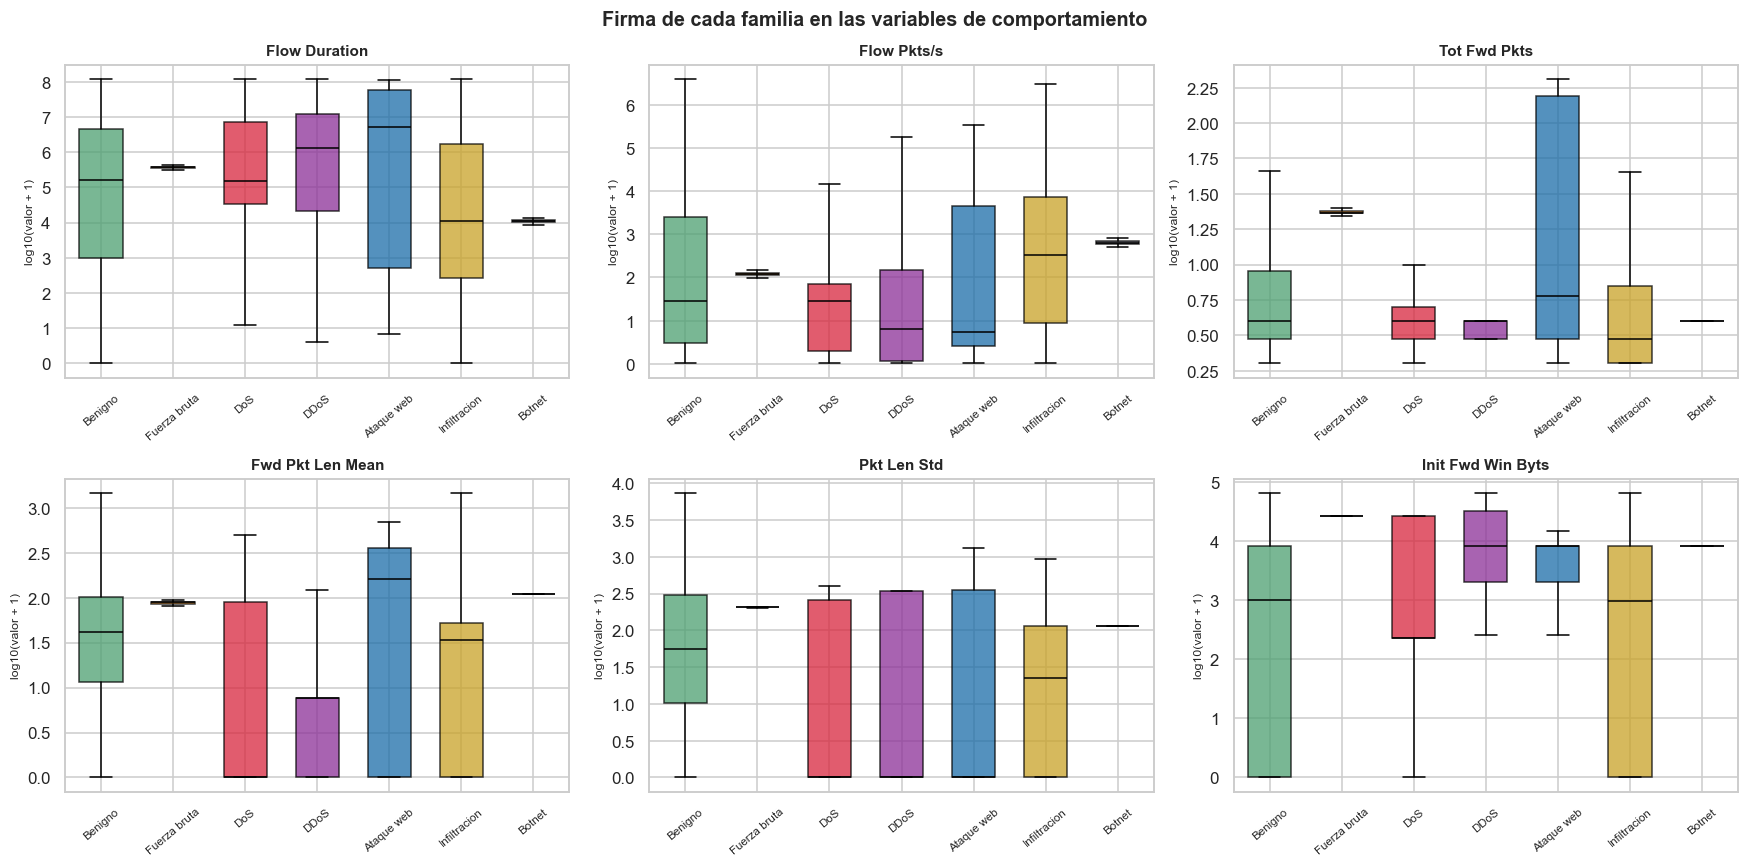

In [17]:
clave = ["Flow Duration", "Flow Pkts/s", "Tot Fwd Pkts", "Fwd Pkt Len Mean",
         "Pkt Len Std", "Init Fwd Win Byts"]
clave = [c for c in clave if c in df.columns]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
orden_fam = ["Benigno"] + [f for f in cfg.FAMILIAS_ATAQUE if f in df["familia"].unique()]

for ax, col in zip(axes.ravel(), clave):
    datos = [np.log10(df.loc[df["familia"] == f, col].clip(lower=0).dropna() + 1)
             for f in orden_fam]
    bp = ax.boxplot(datos, tick_labels=orden_fam, patch_artist=True,
                    showfliers=False, widths=.6)
    for parche, f in zip(bp["boxes"], orden_fam):
        parche.set_facecolor(COLOR_FAM.get(f, "#999"))
        parche.set_alpha(.75)
    for mediana in bp["medians"]:
        mediana.set_color("black")
    ax.set_title(col, fontsize=10)
    ax.set_ylabel("log10(valor + 1)", fontsize=8)
    ax.tick_params(axis="x", rotation=40, labelsize=7.5)

fig.suptitle("Firma de cada familia en las variables de comportamiento", fontsize=13, weight="bold")
guardar("07_boxplots_familias")
plt.show()

> **Insight 5 — cada familia tiene una firma legible.**
> `DoS` muestra duraciones larguísimas con pocos paquetes (*slowloris* dejando
> conexiones colgadas). `DDoS` dispara `Flow Pkts/s`. `Fuerza bruta` tiene
> `Pkt Len Std` casi en cero: manda el mismo paquete miles de veces.
> Y **`Infiltracion` se superpone con `Benigno` en todas las variables** — es la
> confirmación visual de lo que ya avisaba el clustering.

## 3.9 Duplicados: el defecto que casi borra dos ataques

Ya sabemos que el 28,8% de la muestra eran filas repetidas exactas. Pero el
número agregado esconde lo interesante: **la tasa de duplicados no está
repartida de forma pareja entre los ataques, ni de lejos.**

,en la muestra,tras deduplicar,% duplicados
FTP-BruteForce,"100,000",53,99.95%
DoS attacks-SlowHTTPTest,"100,000",54,99.95%
DDOS attack-HOIC,"100,000","46,396",53.60%
SSH-Bruteforce,"100,000","50,199",49.80%
Bot,"100,000","50,955",49.05%
DoS attacks-Hulk,"100,000","52,432",47.57%
Benign,"1,077,982","925,666",14.13%
Infilteration,"161,934","140,610",13.17%
DoS attacks-Slowloris,"10,990","9,712",11.63%
Brute Force -Web,611,553,9.49%


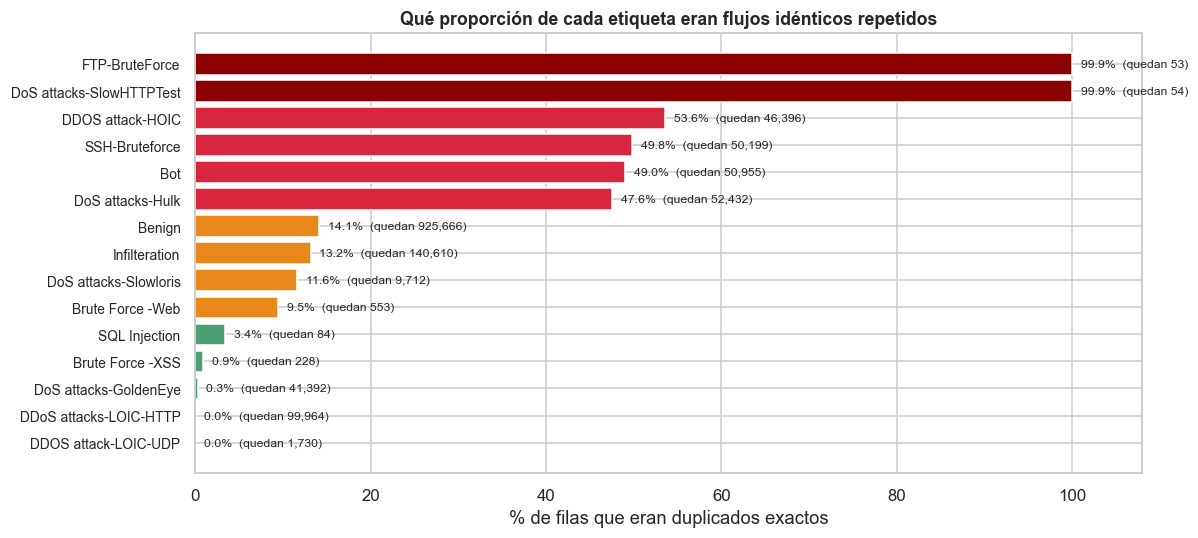

In [18]:
dup = pd.DataFrame({
    "en la muestra": pd.Series(meta["conteo_antes_dedup"]),
    "tras deduplicar": pd.Series(meta["conteo_tras_dedup"]),
}).fillna(0).astype(int)
dup["% duplicados"] = (1 - dup["tras deduplicar"] / dup["en la muestra"]) * 100
dup = dup.sort_values("% duplicados", ascending=False)

display(dup.style.format({"en la muestra": "{:,}", "tras deduplicar": "{:,}",
                          "% duplicados": "{:.2f}%"})
        .background_gradient(subset=["% duplicados"], cmap="Reds"))

fig, ax = plt.subplots(figsize=(11, 5))
colores = ["#8B0000" if v > 99 else ("#D7263D" if v > 40 else "#E8871A" if v > 5 else "#4C9F70")
           for v in dup["% duplicados"]]
ax.barh(range(len(dup)), dup["% duplicados"], color=colores)
ax.set_yticks(range(len(dup)))
ax.set_yticklabels(dup.index, fontsize=9)
ax.invert_yaxis()
ax.set_xlabel("% de filas que eran duplicados exactos")
ax.set_xlim(0, 108)
ax.set_title("Qué proporción de cada etiqueta eran flujos idénticos repetidos", fontsize=11.5)
for i, (v, q) in enumerate(zip(dup["% duplicados"], dup["tras deduplicar"])):
    ax.text(v + 1, i, f"{v:.1f}%  (quedan {q:,})", va="center", fontsize=8)
guardar("08b_duplicados")
plt.show()

> **Insight 6 — dos ataques del dataset son prácticamente una sola fila repetida.**
>
> `FTP-BruteForce` y `DoS attacks-SlowHTTPTest` son **99,95% duplicados
> exactos**: de 100.000 flujos cada uno quedan **53 y 54**. En el otro extremo,
> `DDOS attack-LOIC-UDP` no tiene ni un duplicado.
>
> Tiene sentido: una fuerza bruta de FTP repite exactamente la misma operación
> miles de veces, y CICFlowMeter produce registros idénticos. Pero la
> consecuencia es seria: **esos dos tipos de ataque dejan de existir como
> material de entrenamiento utilizable.**
>
> Un trabajo que no deduplique nunca ve este problema — al contrario, obtiene
> métricas *excelentes* en esas dos clases, porque está evaluando sobre copias
> exactas de lo que memorizó.
>
> **Aquí se nota por qué agrupar en familias fue la decisión correcta:**
> `Fuerza bruta` sobrevive gracias a `SSH-Bruteforce` (50.199 flujos únicos) y
> `DoS` sobrevive gracias a `Hulk` y `GoldenEye`. Con las 14 etiquetas
> originales, dos clases habrían quedado con ~50 ejemplos.

## 3.10 La partición train / test

**No usamos un split aleatorio.** Los flujos de una misma ráfaga de ataque son
casi idénticos entre sí; repartidos al azar, el modelo ve en test algo
prácticamente igual a lo que memorizó en train, y las métricas salen infladas.

Partimos **por tiempo dentro de cada par (día, familia)**: el primer 70% va a
train y el último 30% a test. Así el test de cada familia ocurre *después* de su
train, ninguna ráfaga se reparte entre los dos, y toda familia queda
representada en ambos lados.

**Por qué no basta cortar por día.** Lo intentamos primero y falló:
`Fuerza bruta` se quedó con **53 flujos en test** frente a 50.199 en train. La
razón es que esos ataques son tan repetitivos que el deduplicado se llevó el 75%
de ellos, y los flujos únicos que sobreviven están concentrados al principio de
su día. Con 53 ejemplos cualquier métrica de esa familia sería ruido. Afinar el
corte a (día, familia) lo dejó en 15.076 flujos de test.

particion,test,train,Total
familia,,,
Ataque web,261,604,865
Benigno,277704,647962,925666
Botnet,15287,35668,50955
DDoS,44428,103662,148090
DoS,31078,72512,103590
Fuerza bruta,15076,35176,50252
Infiltracion,42184,98426,140610
Total,426018,994010,1420028


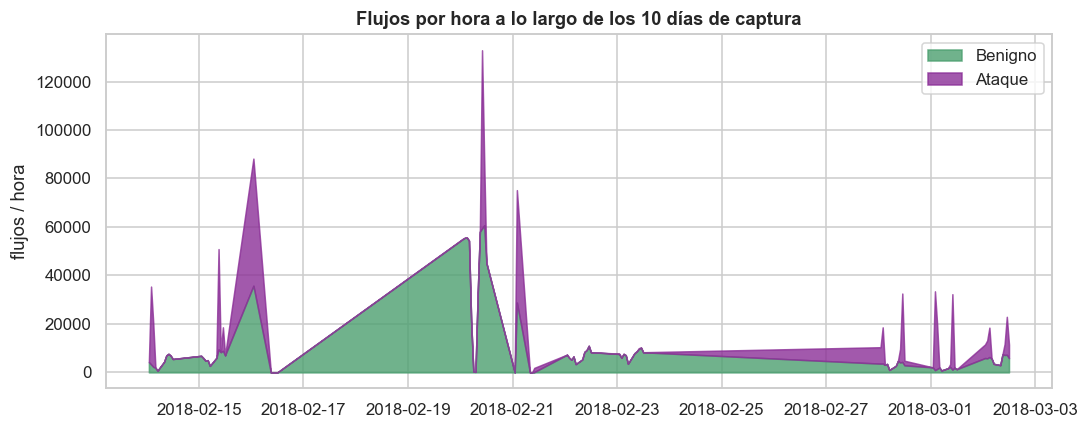

In [19]:
tabla_part = pd.crosstab(df["familia"], df["particion"], margins=True, margins_name="Total")
display(tabla_part)

fig, ax = plt.subplots(figsize=(10, 4))
por_hora = (df.set_index("Timestamp")
              .groupby([pd.Grouper(freq="1h"), "es_ataque"], observed=True)
              .size().unstack(fill_value=0))
ax.fill_between(por_hora.index, 0, por_hora.get(0, 0), color=COLOR_FAM["Benigno"],
                alpha=.8, label="Benigno")
ax.fill_between(por_hora.index, por_hora.get(0, 0),
                por_hora.get(0, 0) + por_hora.get(1, 0), color=COLOR_FAM["DDoS"],
                alpha=.8, label="Ataque")
ax.set_title("Flujos por hora a lo largo de los 10 días de captura")
ax.set_ylabel("flujos / hora"); ax.legend()
guardar("08_linea_temporal")
plt.show()

### Resumen del EDA

| # | Insight | Qué decidió |
|---|---|---|
| 1 | Desbalance de cientos de miles a uno | métricas macro y curvas PR; nunca *accuracy* sola |
| 2 | Cada ataque vive en días específicos | partición por tiempo **dentro** de cada día |
| 3 | `Dst Port` basta para "clasificar" casi todo | se excluye del modelo: era fuga, no señal |
| 4 | K-Means recupera varias familias sin etiquetas | la etapa 1 no supervisada es viable |
| 5 | `Infiltracion` se superpone con `Benigno` | se predice que fallará, y se reporta |
| 6 | Dos ataques son 99,95% duplicados exactos | se reporta; la agrupación en familias los absorbe |

---
# 4. Modelos

## 4.1 Preparación de las matrices

Un detalle que decide la honestidad del experimento: **la etapa 1 no puede ver
ni un solo ataque, ni siquiera para calcular la escala de las variables.**
Por eso hay dos preprocesadores independientes, cada uno ajustado solo con los
datos que su etapa tiene derecho a conocer.

El tráfico benigno de train se parte en dos:
- **ajuste** (80%) — para entrenar los modelos de anomalías
- **calibración** (20%) — para elegir el umbral de decisión

Elegir el umbral sobre los mismos datos de entrenamiento sería hacerse trampa.

In [20]:
from sklearn.model_selection import train_test_split

tr = df[df["particion"] == "train"]
te = df[df["particion"] == "test"]

# ---------- Etapa 1 ----------
benigno_tr = tr[tr["es_ataque"] == 0]
ben_ajuste, ben_calib = train_test_split(
    benigno_tr, test_size=0.20, random_state=cfg.SEMILLA, shuffle=True
)
if len(ben_ajuste) > cfg.N_BENIGNO_E1:
    ben_ajuste = ben_ajuste.sample(cfg.N_BENIGNO_E1, random_state=cfg.SEMILLA)

# Test de la etapa 1: todos los ataques + un tope de benignos.
te_ataques = te[te["es_ataque"] == 1]
te_benignos = te[te["es_ataque"] == 0]
if len(te_benignos) > cfg.N_TEST_BENIGNO:
    te_benignos = te_benignos.sample(cfg.N_TEST_BENIGNO, random_state=cfg.SEMILLA)
te_e1 = pd.concat([te_benignos, te_ataques]).sample(frac=1, random_state=cfg.SEMILLA)

from sklearn.preprocessing import FunctionTransformer, StandardScaler


def log_con_signo(X):
    """log(1+|x|) conservando el signo. Domina las colas sin recortar nada."""
    return np.sign(X) * np.log1p(np.abs(X))


# OJO: aqui NO se usa QuantileTransformer, y es una decision deliberada.
#
# La transformacion por cuantiles, ajustada solo con trafico benigno, RECORTA
# cualquier valor que caiga fuera del rango observado: lo manda al cuantil
# minimo o maximo del benigno. Para un detector de anomalias eso es
# autodestructivo, porque "estar fuera del rango normal" es justo la senal que
# tiene que detectar. Un flujo con un ritmo de paquetes mil veces superior a lo
# normal quedaba indistinguible del benigno mas extremo.
#
# Lo medimos: con cuantiles, el One-Class SVM daba ROC-AUC 0.38 (PEOR que el
# azar) y el Isolation Forest 0.54. Con log + estandarizacion los valores
# extremos siguen siendo extremos.
pre_e1 = Pipeline([
    ("imputar", SimpleImputer(strategy="median")),
    ("log", FunctionTransformer(log_con_signo, feature_names_out="one-to-one")),
    ("escalar", StandardScaler()),
])
# float32 y no float64: la mitad de memoria y ninguna diferencia practica en
# datos que vienen de contadores de red. En un portatil de 16 GB esto importa.
Xe1_ajuste = pre_e1.fit_transform(ben_ajuste[VARIABLES]).astype(np.float32)   # SOLO benignos
Xe1_calib = pre_e1.transform(ben_calib[VARIABLES]).astype(np.float32)
Xe1_test = pre_e1.transform(te_e1[VARIABLES]).astype(np.float32)
ye1_test = te_e1["es_ataque"].to_numpy()

print("ETAPA 1 - deteccion de anomalias")
print(f"  ajuste      : {Xe1_ajuste.shape[0]:>8,} flujos (100% benignos)")
print(f"  calibracion : {Xe1_calib.shape[0]:>8,} flujos (100% benignos)")
print(f"  test        : {Xe1_test.shape[0]:>8,} flujos "
      f"({(ye1_test == 0).sum():,} benignos + {(ye1_test == 1).sum():,} ataques)")


# ---------- Etapa 2 ----------
def submuestra_estratificada(datos, n, col="familia", semilla=cfg.SEMILLA):
    """Submuestra hasta ~n filas repartidas entre las clases, sin perder las chicas.

    Reparto equitativo por clase (n / numero de clases) con piso de 50 filas: asi
    las familias diminutas sobreviven y las enormes no se comen la muestra.
    """
    if len(datos) <= n:
        return datos
    n_clases = datos[col].nunique()
    return muestrear_por_grupo(datos, n // n_clases, col=col, minimo=50, semilla=semilla)


ataques_tr = tr[tr["es_ataque"] == 1]
ataques_te = te[te["es_ataque"] == 1]

e2_tr = submuestra_estratificada(ataques_tr, cfg.N_E2_TRAIN)
e2_te = submuestra_estratificada(ataques_te, cfg.N_E2_TEST)

pre_e2 = Pipeline([
    ("imputar", SimpleImputer(strategy="median")),
    ("escalar", QuantileTransformer(output_distribution="normal", n_quantiles=1000,
                                    random_state=cfg.SEMILLA, subsample=200_000)),
])
Xe2_tr = pre_e2.fit_transform(e2_tr[VARIABLES]).astype(np.float32)
Xe2_te = pre_e2.transform(e2_te[VARIABLES]).astype(np.float32)
ye2_tr = e2_tr["familia"].to_numpy()
ye2_te = e2_te["familia"].to_numpy()

# Las copias intermedias del DataFrame ya cumplieron: `tr` y `te` juntas pesan
# casi tanto como `df`. Se liberan antes de entrenar, que es donde mas aprieta.
del tr, te, te_ataques, te_benignos, benigno_tr
gc.collect()

print("\nETAPA 2 - clasificacion de la familia")
print(f"  train : {Xe2_tr.shape[0]:>8,} flujos de ataque")
print(f"  test  : {Xe2_te.shape[0]:>8,} flujos de ataque")
print("\n  reparto por familia:")
rep = pd.DataFrame({"train": pd.Series(ye2_tr).value_counts(),
                    "test": pd.Series(ye2_te).value_counts()}).fillna(0).astype(int)
display(rep)

ETAPA 1 - deteccion de anomalias
  ajuste      :  150,000 flujos (100% benignos)
  calibracion :  129,593 flujos (100% benignos)
  test        :  208,314 flujos (60,000 benignos + 148,314 ataques)



ETAPA 2 - clasificacion de la familia
  train :  100,604 flujos de ataque
  test  :   50,261 flujos de ataque

  reparto por familia:


,train,test
Botnet,20000,10000
DDoS,20000,10000
DoS,20000,10000
Fuerza bruta,20000,10000
Infiltracion,20000,10000
Ataque web,604,261


## 4.2 Etapa 1 — cinco enfoques para la misma pregunta

Los cuatro primeros son **no supervisados**: aprenden solo del tráfico benigno.
El quinto es un **supervisado** que sí ve las etiquetas de ataque: no es parte
del sistema propuesto, está ahí como **techo de referencia** para saber cuánto
cuesta la honestidad de no usar etiquetas.

| Modelo | Cómo funciona | Ventaja | Limitación |
|---|---|---|---|
| **Isolation Forest** | construye árboles con cortes aleatorios; lo raro se aísla en pocos cortes | escala a millones de filas, no asume forma de los datos | pierde sensibilidad ante anomalías "locales" dentro de una zona densa |
| **One-Class SVM** | busca una frontera que envuelva los datos normales en un espacio de kernel | frontera flexible, bien fundamentado teóricamente | coste ~O(n²): obliga a submuestrear |
| **Local Outlier Factor** | compara la densidad local de un punto con la de sus vecinos | detecta lo que Isolation Forest no ve: anomalías locales | caro en predicción, sensible a `n_neighbors` |
| **Autoencoder** | red que comprime y reconstruye; lo normal se reconstruye bien, lo raro no | captura relaciones no lineales entre variables | más hiperparámetros, entrenamiento más lento |
| *Random Forest (referencia)* | *clasificador supervisado benigno vs. ataque* | *techo de desempeño alcanzable* | *necesita ataques etiquetados: no existen en la práctica* |

Todos producen una **puntuación continua de anomalía** (más alto = más raro),
no una decisión. El umbral se elige después, en función del presupuesto de
falsas alarmas.

In [21]:
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.neighbors import LocalOutlierFactor
from sklearn.neural_network import MLPRegressor
from sklearn.svm import OneClassSVM

rng = np.random.default_rng(cfg.SEMILLA)


def sub(X, n):
    if X.shape[0] <= n:
        return X
    return X[rng.choice(X.shape[0], n, replace=False)]


modelos_e1 = {}
tiempos_e1 = {}

# --- 1. Isolation Forest ---
t0 = time.perf_counter()
iforest = IsolationForest(n_estimators=300, max_samples=256, contamination="auto",
                          random_state=cfg.SEMILLA, n_jobs=-1)
iforest.fit(Xe1_ajuste)
tiempos_e1["Isolation Forest"] = time.perf_counter() - t0
modelos_e1["Isolation Forest"] = lambda X, m=iforest: -m.score_samples(X)
print(f"Isolation Forest   entrenado en {tiempos_e1['Isolation Forest']:.1f}s "
      f"sobre {Xe1_ajuste.shape[0]:,} flujos")

# --- 2. One-Class SVM ---
X_ocsvm = sub(Xe1_ajuste, cfg.N_OCSVM)
t0 = time.perf_counter()
ocsvm = OneClassSVM(kernel="rbf", gamma="scale", nu=0.05)
ocsvm.fit(X_ocsvm)
tiempos_e1["One-Class SVM"] = time.perf_counter() - t0
modelos_e1["One-Class SVM"] = lambda X, m=ocsvm: -m.decision_function(X)
print(f"One-Class SVM      entrenado en {tiempos_e1['One-Class SVM']:.1f}s "
      f"sobre {X_ocsvm.shape[0]:,} flujos (submuestra por coste cuadratico)")

# --- 3. Local Outlier Factor ---
X_lof = sub(Xe1_ajuste, cfg.N_LOF)
t0 = time.perf_counter()
lof = LocalOutlierFactor(n_neighbors=20, novelty=True, n_jobs=-1)
lof.fit(X_lof)
tiempos_e1["Local Outlier Factor"] = time.perf_counter() - t0
modelos_e1["Local Outlier Factor"] = lambda X, m=lof: -m.decision_function(X)
print(f"LOF                entrenado en {tiempos_e1['Local Outlier Factor']:.1f}s "
      f"sobre {X_lof.shape[0]:,} flujos")

# --- 4. Autoencoder ---
# Cuello de botella de 8 neuronas: la red se ve forzada a quedarse solo con la
# estructura esencial del trafico normal. Lo que no encaje se reconstruye mal.
X_ae = sub(Xe1_ajuste, cfg.N_AUTOENCODER)
t0 = time.perf_counter()
autoenc = MLPRegressor(hidden_layer_sizes=(32, 8, 32), activation="relu",
                       solver="adam", learning_rate_init=1e-3, batch_size=512,
                       max_iter=60, early_stopping=True, n_iter_no_change=5,
                       random_state=cfg.SEMILLA)
autoenc.fit(X_ae, X_ae)
tiempos_e1["Autoencoder"] = time.perf_counter() - t0
modelos_e1["Autoencoder"] = lambda X, m=autoenc: ((X - m.predict(X)) ** 2).mean(axis=1)
print(f"Autoencoder        entrenado en {tiempos_e1['Autoencoder']:.1f}s "
      f"sobre {X_ae.shape[0]:,} flujos ({autoenc.n_iter_} epocas)")

# --- 5. Random Forest supervisado (techo de referencia) ---
ref_tr = pd.concat([ben_ajuste, submuestra_estratificada(ataques_tr, 60_000)])
X_ref = pre_e1.transform(ref_tr[VARIABLES])
y_ref = ref_tr["es_ataque"].to_numpy()
t0 = time.perf_counter()
rf_bin = RandomForestClassifier(n_estimators=200, min_samples_leaf=2,
                                class_weight="balanced", n_jobs=-1,
                                random_state=cfg.SEMILLA)
rf_bin.fit(X_ref, y_ref)
tiempos_e1["Random Forest (referencia)"] = time.perf_counter() - t0
modelos_e1["Random Forest (referencia)"] = lambda X, m=rf_bin: m.predict_proba(X)[:, 1]
print(f"RF supervisado     entrenado en {tiempos_e1['Random Forest (referencia)']:.1f}s "
      f"(usa etiquetas: NO es parte del sistema propuesto)")

Isolation Forest   entrenado en 1.1s sobre 150,000 flujos


One-Class SVM      entrenado en 2.5s sobre 20,000 flujos (submuestra por coste cuadratico)


LOF                entrenado en 4.3s sobre 50,000 flujos


Autoencoder        entrenado en 11.3s sobre 100,000 flujos (60 epocas)


RF supervisado     entrenado en 27.9s (usa etiquetas: NO es parte del sistema propuesto)


## 4.3 Etapa 2 — seis enfoques para nombrar el ataque

Aquí sí hay etiquetas, y la diversidad de enfoques es deliberada: cada familia
de método tiene una idea distinta de qué significa "parecido".

| Modelo | Familia de método | Por qué lo incluimos |
|---|---|---|
| **Random Forest** | ensamble por *bagging* de árboles | robusto sin escalado, maneja el desbalance con `class_weight` |
| **LightGBM** | *boosting* por gradiente (histogramas) | suele ser el mejor en datos tabulares; muy rápido |
| **XGBoost** | *boosting* por gradiente (otra implementación) | regularización distinta: contraste útil contra LightGBM |
| **k-NN** | basado en instancias | no asume ninguna forma; mide literalmente "a qué se parece" |
| **MLP** | red neuronal | capta interacciones no lineales que los árboles aproximan en escalones |
| **Regresión logística** | lineal | **línea base obligatoria**: si lo complejo no le gana, no se justifica |

Todos devuelven **probabilidades**, no solo etiquetas. Eso es justo lo que
después permite decir *"no sé"* cuando ninguna clase convence (§7).

In [22]:
import lightgbm as lgb
import xgboost as xgb
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import LabelEncoder

codif = LabelEncoder().fit(ye2_tr)
ye2_tr_num = codif.transform(ye2_tr)
CLASES_E2 = list(codif.classes_)

# Submuestra para los modelos que no escalan (kNN y MLP).
idx_lentos = rng.choice(Xe2_tr.shape[0], min(cfg.N_E2_LENTOS, Xe2_tr.shape[0]), replace=False)

defs_e2 = {
    "Random Forest": (
        RandomForestClassifier(n_estimators=300, min_samples_leaf=2, class_weight="balanced",
                               n_jobs=-1, random_state=cfg.SEMILLA),
        "completo"),
    "LightGBM": (
        lgb.LGBMClassifier(n_estimators=400, learning_rate=0.08, num_leaves=63,
                           class_weight="balanced", n_jobs=-1, verbose=-1,
                           random_state=cfg.SEMILLA),
        "completo"),
    "XGBoost": (
        xgb.XGBClassifier(n_estimators=400, learning_rate=0.08, max_depth=8,
                          subsample=0.9, colsample_bytree=0.9, tree_method="hist",
                          n_jobs=-1, random_state=cfg.SEMILLA),
        "completo"),
    "k-NN": (
        KNeighborsClassifier(n_neighbors=5, weights="distance", n_jobs=-1),
        "reducido"),
    "MLP": (
        MLPClassifier(hidden_layer_sizes=(128, 64), max_iter=80, batch_size=512,
                      early_stopping=True, n_iter_no_change=8, random_state=cfg.SEMILLA),
        "reducido"),
    "Regresion logistica": (
        LogisticRegression(max_iter=1000, class_weight="balanced", n_jobs=-1,
                           random_state=cfg.SEMILLA),
        "completo"),
}

modelos_e2, tiempos_e2 = {}, {}
for nombre, (modelo, alcance) in defs_e2.items():
    if alcance == "reducido":
        Xf, yf = Xe2_tr[idx_lentos], ye2_tr_num[idx_lentos]
    else:
        Xf, yf = Xe2_tr, ye2_tr_num
    t0 = time.perf_counter()
    modelo.fit(Xf, yf)
    tiempos_e2[nombre] = time.perf_counter() - t0
    modelos_e2[nombre] = modelo
    print(f"{nombre:<22} {tiempos_e2[nombre]:>7.1f}s   sobre {Xf.shape[0]:>7,} flujos")

Random Forest              8.9s   sobre 100,604 flujos


LightGBM                  19.9s   sobre 100,604 flujos


XGBoost                   16.6s   sobre 100,604 flujos
k-NN                       0.0s   sobre  40,000 flujos


MLP                        2.0s   sobre  40,000 flujos


Regresion logistica       30.8s   sobre 100,604 flujos


---
# 5. Comparación de métricas

## 5.1 Etapa 1: qué métrica y por qué

- **ROC-AUC** — capacidad de ordenar: dado un ataque y un flujo benigno al azar,
  ¿con qué probabilidad el modelo le asigna mayor puntuación al ataque?
- **PR-AUC** (precisión media) — **la métrica que manda con clases desbalanceadas.**
  La ROC-AUC se ve optimista cuando la clase positiva es rara; la PR-AUC no.
- **Recall a FPR = 1%** — la métrica operativa. Fijamos el presupuesto de falsas
  alarmas que un SOC puede tolerar (1% del tráfico benigno) y preguntamos:
  *¿cuántos ataques atrapas sin pasarte de ese presupuesto?*

El umbral de cada modelo se fija con el **conjunto de calibración** (benignos que
ningún modelo vio al entrenar), nunca con el test.

In [23]:
from sklearn.metrics import (average_precision_score, precision_recall_curve,
                             roc_auc_score, roc_curve)

filas_e1, curvas_e1 = [], {}

for nombre, puntuar in modelos_e1.items():
    s_calib = puntuar(Xe1_calib)
    s_test = puntuar(Xe1_test)

    # Umbral = percentil (1 - FPR) de las puntuaciones de los benignos de calibracion.
    umbral = float(np.quantile(s_calib, 1 - cfg.FPR_OBJETIVO))
    alerta = s_test >= umbral

    vp = int(((alerta == 1) & (ye1_test == 1)).sum())
    fp = int(((alerta == 1) & (ye1_test == 0)).sum())
    fn = int(((alerta == 0) & (ye1_test == 1)).sum())
    vn = int(((alerta == 0) & (ye1_test == 0)).sum())

    filas_e1.append({
        "modelo": nombre,
        "ROC-AUC": roc_auc_score(ye1_test, s_test),
        "PR-AUC": average_precision_score(ye1_test, s_test),
        "Recall @ FPR 1%": vp / max(vp + fn, 1),
        "Precision en ese punto": vp / max(vp + fp, 1),
        "FPR real": fp / max(fp + vn, 1),
        "Entrenamiento (s)": tiempos_e1[nombre],
    })
    curvas_e1[nombre] = (roc_curve(ye1_test, s_test), precision_recall_curve(ye1_test, s_test))

tabla_e1 = pd.DataFrame(filas_e1).set_index("modelo").sort_values("PR-AUC", ascending=False)
display(tabla_e1.style.format({
    "ROC-AUC": "{:.4f}", "PR-AUC": "{:.4f}", "Recall @ FPR 1%": "{:.4f}",
    "Precision en ese punto": "{:.4f}", "FPR real": "{:.4f}", "Entrenamiento (s)": "{:.1f}",
}).background_gradient(subset=["PR-AUC"], cmap="Greens"))

,ROC-AUC,PR-AUC,Recall @ FPR 1%,Precision en ese punto,FPR real,Entrenamiento (s)
modelo,,,,,,
Random Forest (referencia),0.9451,0.9794,0.7695,0.9925,0.0143,27.9
Autoencoder,0.8260,0.9012,0.0741,0.9445,0.0108,11.3
Local Outlier Factor,0.7778,0.9006,0.2215,0.9791,0.0117,4.3
Isolation Forest,0.6213,0.7775,0.0539,0.9239,0.0110,1.1
One-Class SVM,0.4095,0.6896,0.0716,0.9395,0.0114,2.5


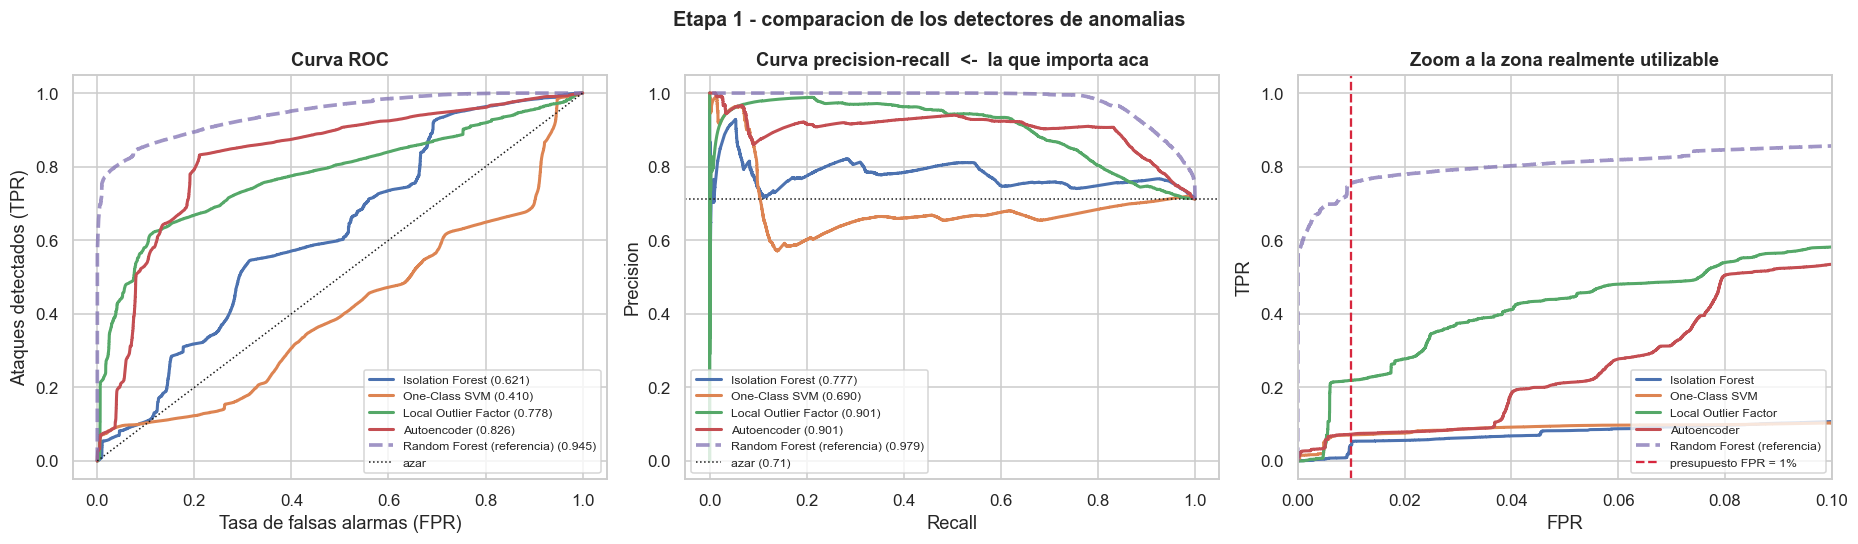

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for nombre, ((fpr, tpr, _), (prec, rec, _)) in curvas_e1.items():
    es_ref = "referencia" in nombre
    estilo = dict(lw=2.4, ls="--", alpha=.75) if es_ref else dict(lw=2)
    axes[0].plot(fpr, tpr, label=f"{nombre} ({tabla_e1.loc[nombre, 'ROC-AUC']:.3f})", **estilo)
    axes[1].plot(rec, prec, label=f"{nombre} ({tabla_e1.loc[nombre, 'PR-AUC']:.3f})", **estilo)

axes[0].plot([0, 1], [0, 1], "k:", lw=1, label="azar")
axes[0].set_xlabel("Tasa de falsas alarmas (FPR)")
axes[0].set_ylabel("Ataques detectados (TPR)")
axes[0].set_title("Curva ROC")
axes[0].legend(fontsize=8, loc="lower right")

base = ye1_test.mean()
axes[1].axhline(base, color="k", ls=":", lw=1, label=f"azar ({base:.2f})")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Curva precision-recall  <-  la que importa aca")
axes[1].legend(fontsize=8, loc="lower left")

# Zoom a la zona operativa: nadie opera un SOC con 50% de falsas alarmas.
for nombre, ((fpr, tpr, _), _) in curvas_e1.items():
    es_ref = "referencia" in nombre
    axes[2].plot(fpr, tpr, lw=2.4 if es_ref else 2, ls="--" if es_ref else "-",
                 alpha=.75 if es_ref else 1, label=nombre)
axes[2].axvline(cfg.FPR_OBJETIVO, color="#D7263D", ls="--", lw=1.5,
                label=f"presupuesto FPR = {cfg.FPR_OBJETIVO:.0%}")
axes[2].set_xlim(0, 0.10)
axes[2].set_xlabel("FPR")
axes[2].set_ylabel("TPR")
axes[2].set_title("Zoom a la zona realmente utilizable")
axes[2].legend(fontsize=8, loc="lower right")

fig.suptitle("Etapa 1 - comparacion de los detectores de anomalias", fontsize=13, weight="bold")
guardar("09_etapa1_curvas")
plt.show()

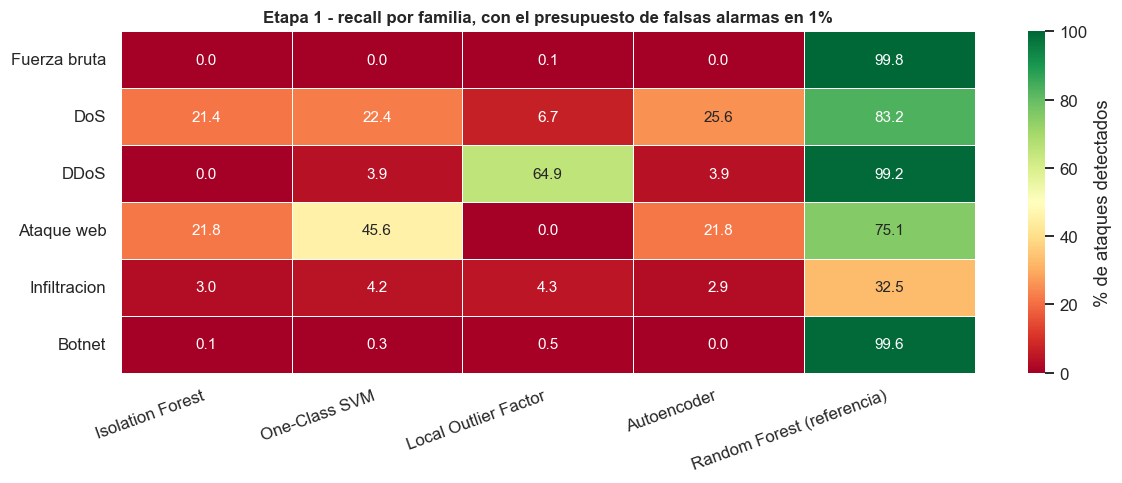

Mejor detector NO supervisado (el que si forma parte del sistema): Autoencoder
Techo de referencia supervisado: PR-AUC = 0.9794


In [25]:
# Que familias atrapa cada detector, al umbral del presupuesto de falsas alarmas
det_por_familia = {}
umbrales_e1 = {}
for nombre, puntuar in modelos_e1.items():
    umbral = float(np.quantile(puntuar(Xe1_calib), 1 - cfg.FPR_OBJETIVO))
    umbrales_e1[nombre] = umbral
    s = puntuar(Xe1_test)
    aux = te_e1.assign(detectado=(s >= umbral))
    det_por_familia[nombre] = (aux[aux["es_ataque"] == 1]
                               .groupby("familia", observed=True)["detectado"].mean())

tabla_det = pd.DataFrame(det_por_familia).reindex(cfg.FAMILIAS_ATAQUE).dropna(how="all")

fig, ax = plt.subplots(figsize=(11, 4.5))
sns.heatmap(tabla_det * 100, annot=True, fmt=".1f", cmap="RdYlGn", vmin=0, vmax=100,
            ax=ax, cbar_kws={"label": "% de ataques detectados"}, linewidths=.5)
ax.set_title(f"Etapa 1 - recall por familia, con el presupuesto de falsas alarmas en "
             f"{cfg.FPR_OBJETIVO:.0%}", fontsize=11)
ax.set_ylabel("")
plt.xticks(rotation=20, ha="right")
guardar("10_etapa1_recall_familia")
plt.show()

MEJOR_E1 = [n for n in tabla_e1.index if "referencia" not in n][0]
print(f"Mejor detector NO supervisado (el que si forma parte del sistema): {MEJOR_E1}")
print(f"Techo de referencia supervisado: PR-AUC = "
      f"{tabla_e1.loc['Random Forest (referencia)', 'PR-AUC']:.4f}")

## 5.2 Etapa 2: clasificación de la familia

Métricas y por qué cada una:

- **Accuracy** — se reporta por completitud, pero está dominada por las clases
  grandes. No se usa para decidir.
- **F1 macro** — promedia el F1 de cada familia **dándoles el mismo peso.**
  Esta es la métrica de decisión: `Ataque web` tiene cientos de flujos frente a
  cientos de miles de `DDoS`, y nos importa igual.
- **F1 ponderado** — el término medio; contrastarlo con el macro muestra cuánto
  del desempeño viene solo de las clases grandes.
- **Recall por familia** — qué proporción de cada ataque se reconoce. Es lo que
  de verdad le dice al analista si puede confiar en la etiqueta.

In [26]:
from sklearn.metrics import (ConfusionMatrixDisplay, balanced_accuracy_score,
                             classification_report, confusion_matrix)

filas_e2, preds_e2 = [], {}

for nombre, modelo in modelos_e2.items():
    t0 = time.perf_counter()
    pred_num = modelo.predict(Xe2_te)
    t_pred = time.perf_counter() - t0
    pred = codif.inverse_transform(pred_num)
    preds_e2[nombre] = pred

    filas_e2.append({
        "modelo": nombre,
        "Accuracy": accuracy_score(ye2_te, pred),
        "F1 macro": f1_score(ye2_te, pred, average="macro"),
        "F1 ponderado": f1_score(ye2_te, pred, average="weighted"),
        "Accuracy balanceada": balanced_accuracy_score(ye2_te, pred),
        "Entrenamiento (s)": tiempos_e2[nombre],
        "Prediccion (s)": t_pred,
    })

tabla_e2 = pd.DataFrame(filas_e2).set_index("modelo").sort_values("F1 macro", ascending=False)
display(tabla_e2.style.format({
    "Accuracy": "{:.4f}", "F1 macro": "{:.4f}", "F1 ponderado": "{:.4f}",
    "Accuracy balanceada": "{:.4f}", "Entrenamiento (s)": "{:.1f}", "Prediccion (s)": "{:.2f}",
}).background_gradient(subset=["F1 macro"], cmap="Greens"))

MEJOR_E2 = tabla_e2.index[0]
print(f"\nMejor modelo de la etapa 2 por F1 macro: {MEJOR_E2}")

,Accuracy,F1 macro,F1 ponderado,Accuracy balanceada,Entrenamiento (s),Prediccion (s)
modelo,,,,,,
LightGBM,0.9685,0.9688,0.9683,0.9724,19.9,1.17
XGBoost,0.9696,0.9676,0.9695,0.9677,16.6,0.36
Random Forest,0.9661,0.9573,0.9661,0.9635,8.9,0.28
k-NN,0.9650,0.9511,0.9649,0.9520,0.0,3.46
MLP,0.9435,0.8998,0.9440,0.9061,2.0,0.03
Regresion logistica,0.9270,0.8280,0.9358,0.9345,30.8,0.02



Mejor modelo de la etapa 2 por F1 macro: LightGBM


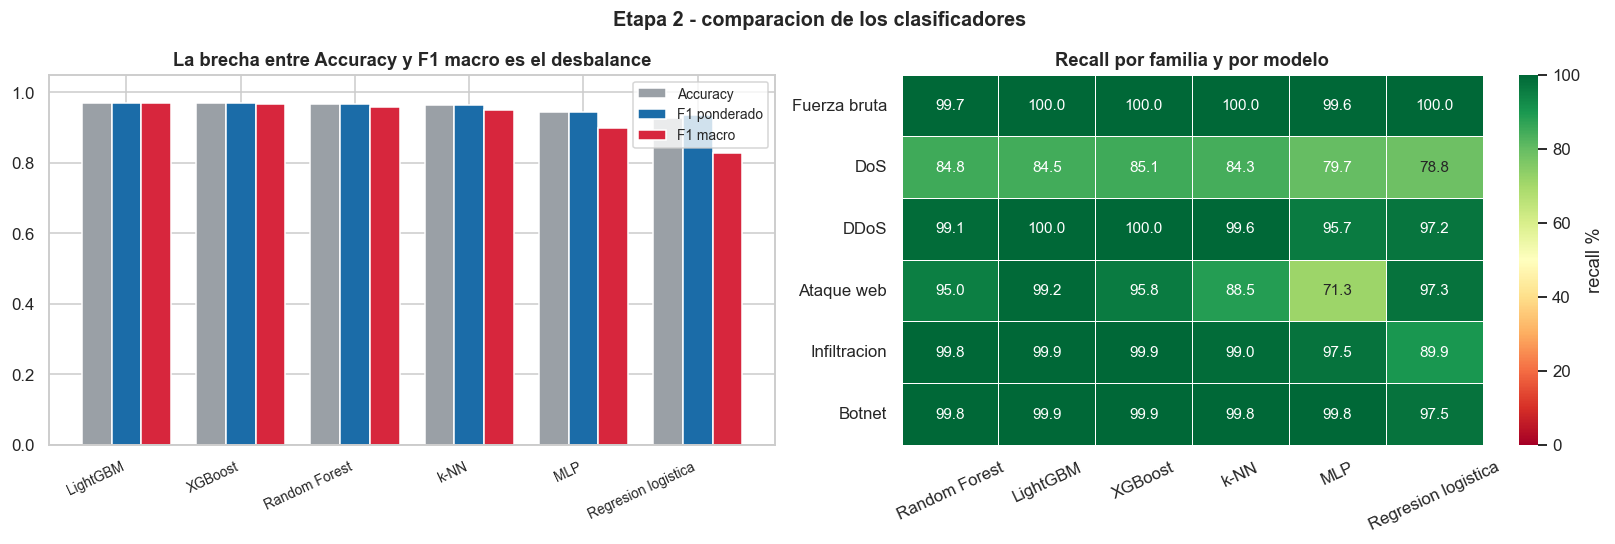

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

x = np.arange(len(tabla_e2))
ancho = 0.26
for i, (col, color) in enumerate([("Accuracy", "#9AA0A6"), ("F1 ponderado", "#1B6CA8"),
                                  ("F1 macro", "#D7263D")]):
    axes[0].bar(x + (i - 1) * ancho, tabla_e2[col], ancho, label=col, color=color)
axes[0].set_xticks(x)
axes[0].set_xticklabels(tabla_e2.index, rotation=25, ha="right", fontsize=9)
axes[0].set_ylim(0, 1.05)
axes[0].legend(fontsize=9)
axes[0].set_title("La brecha entre Accuracy y F1 macro es el desbalance")

# Recall por familia y por modelo
recalls = {}
for nombre, pred in preds_e2.items():
    rp = classification_report(ye2_te, pred, output_dict=True, zero_division=0)
    recalls[nombre] = {f: rp[f]["recall"] for f in CLASES_E2 if f in rp}
tabla_rec = pd.DataFrame(recalls).reindex([f for f in cfg.FAMILIAS_ATAQUE if f in CLASES_E2])

sns.heatmap(tabla_rec * 100, annot=True, fmt=".1f", cmap="RdYlGn", vmin=0, vmax=100,
            ax=axes[1], cbar_kws={"label": "recall %"}, linewidths=.5)
axes[1].set_title("Recall por familia y por modelo")
axes[1].set_ylabel("")
axes[1].tick_params(axis="x", rotation=25)

fig.suptitle("Etapa 2 - comparacion de los clasificadores", fontsize=13, weight="bold")
guardar("11_etapa2_comparacion")
plt.show()

Reporte detallado - LightGBM



              precision    recall  f1-score   support

  Ataque web     0.9522    0.9923    0.9719       261
      Botnet     0.9996    0.9985    0.9990     10000
        DDoS     1.0000    0.9998    0.9999     10000
         DoS     1.0000    0.8445    0.9157     10000
Fuerza bruta     0.9949    1.0000    0.9975     10000
Infiltracion     0.8683    0.9991    0.9291     10000

    accuracy                         0.9685     50261
   macro avg     0.9692    0.9724    0.9688     50261
weighted avg     0.9725    0.9685    0.9683     50261



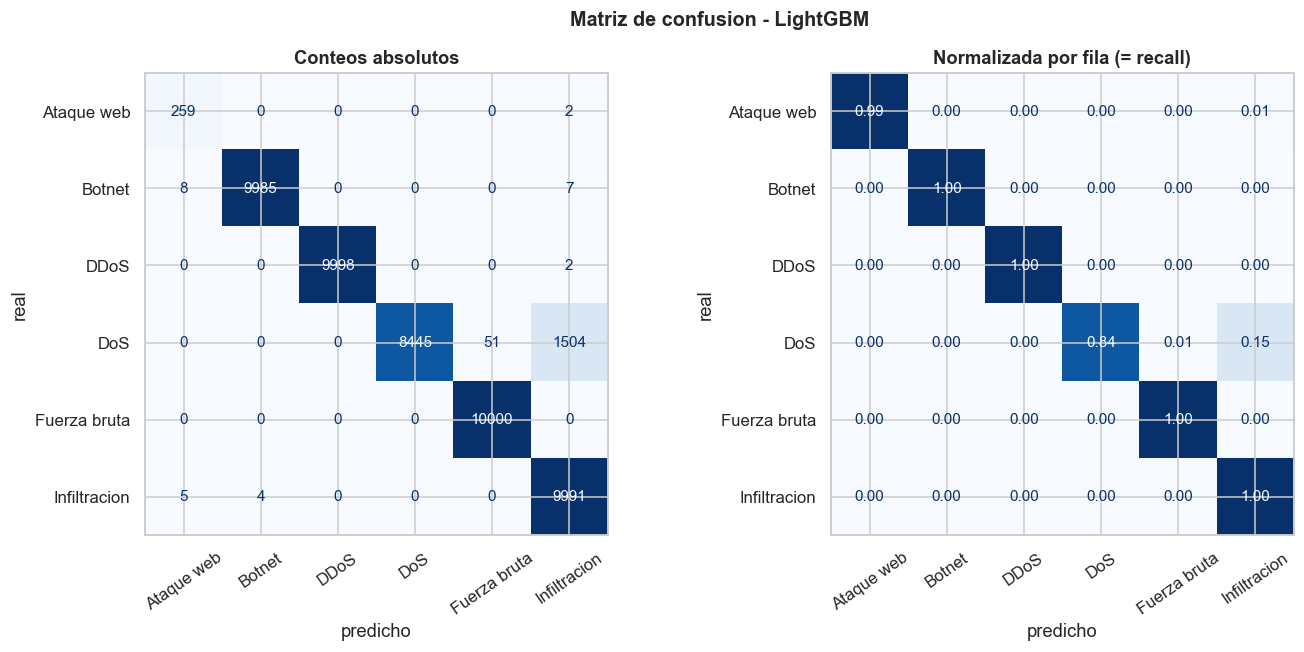

In [28]:
print(f"Reporte detallado - {MEJOR_E2}\n")
print(classification_report(ye2_te, preds_e2[MEJOR_E2], zero_division=0, digits=4))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, norm, titulo in [(axes[0], None, "Conteos absolutos"),
                         (axes[1], "true", "Normalizada por fila (= recall)")]:
    cm = confusion_matrix(ye2_te, preds_e2[MEJOR_E2], labels=CLASES_E2, normalize=norm)
    ConfusionMatrixDisplay(cm, display_labels=CLASES_E2).plot(
        ax=ax, cmap="Blues", colorbar=False,
        values_format="d" if norm is None else ".2f", xticks_rotation=35)
    ax.set_title(titulo)
    ax.set_xlabel("predicho")
    ax.set_ylabel("real")

fig.suptitle(f"Matriz de confusion - {MEJOR_E2}", fontsize=13, weight="bold")
guardar("12_matriz_confusion")
plt.show()

---
# 6. Optimización de hiperparámetros

Se usan **tres técnicas**, cada una donde tiene sentido:

| Técnica | Dónde | Por qué ahí |
|---|---|---|
| **RandomizedSearchCV** | LightGBM (etapa 2) | el espacio tiene 7 dimensiones, varias continuas; una rejilla completa sería inabordable y la búsqueda aleatoria cubre mejor el espacio con el mismo presupuesto |
| **GridSearchCV** | Random Forest (etapa 2) | pocos parámetros y discretos: la rejilla sí es exhaustiva y barata |
| **Rejilla manual + ROC-AUC** | Isolation Forest (etapa 1) | **no se puede usar `GridSearchCV`**: el modelo se entrena sin etiquetas, así que no hay `y` para la validación cruzada. Se evalúa cada configuración sobre el conjunto de **calibración** |

Validación cruzada estratificada de 3 pliegues y `f1_macro` como criterio,
coherente con lo decidido en §5.2.

In [29]:
from scipy.stats import loguniform, randint, uniform
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, StratifiedKFold

# Submuestra para la busqueda: la validacion cruzada multiplica el coste por 3.
idx_b = rng.choice(Xe2_tr.shape[0], min(cfg.N_BUSQUEDA, Xe2_tr.shape[0]), replace=False)
Xb, yb = Xe2_tr[idx_b], ye2_tr_num[idx_b]
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=cfg.SEMILLA)

print(f"Busqueda sobre {Xb.shape[0]:,} flujos, 3 pliegues, criterio = f1_macro\n")

espacio_lgb = {
    "n_estimators": randint(150, 700),
    "learning_rate": loguniform(0.02, 0.3),
    "num_leaves": randint(15, 160),
    "min_child_samples": randint(5, 80),
    "subsample": uniform(0.6, 0.4),
    "colsample_bytree": uniform(0.6, 0.4),
    "reg_lambda": loguniform(1e-3, 10),
}
t0 = time.perf_counter()
busq_aleatoria = RandomizedSearchCV(
    lgb.LGBMClassifier(class_weight="balanced", n_jobs=-1, verbose=-1,
                       random_state=cfg.SEMILLA),
    espacio_lgb, n_iter=25, scoring="f1_macro", cv=cv,
    random_state=cfg.SEMILLA, n_jobs=1, refit=True, verbose=0,
)
busq_aleatoria.fit(Xb, yb)
print(f"RandomizedSearchCV - LightGBM   ({time.perf_counter() - t0:.0f}s, 25 combinaciones)")
print(f"  mejor f1_macro en CV : {busq_aleatoria.best_score_:.4f}")
for k, v in busq_aleatoria.best_params_.items():
    print(f"    {k:<20} {v if not isinstance(v, float) else round(v, 4)}")

Busqueda sobre 40,000 flujos, 3 pliegues, criterio = f1_macro



RandomizedSearchCV - LightGBM   (285s, 25 combinaciones)
  mejor f1_macro en CV : 0.9938
    colsample_bytree     0.7694
    learning_rate        0.0583
    min_child_samples    12
    n_estimators         621
    num_leaves           77
    reg_lambda           1.8275
    subsample            0.8827


In [30]:
rejilla_rf = {
    "n_estimators": [200, 400],
    "max_depth": [None, 20],
    "min_samples_leaf": [1, 2, 5],
    "max_features": ["sqrt", 0.3],
}
t0 = time.perf_counter()
busq_rejilla = GridSearchCV(
    RandomForestClassifier(class_weight="balanced", n_jobs=-1, random_state=cfg.SEMILLA),
    rejilla_rf, scoring="f1_macro", cv=cv, n_jobs=1, refit=True, verbose=0,
)
busq_rejilla.fit(Xb, yb)
n_comb = int(np.prod([len(v) for v in rejilla_rf.values()]))
print(f"GridSearchCV - Random Forest    ({time.perf_counter() - t0:.0f}s, {n_comb} combinaciones)")
print(f"  mejor f1_macro en CV : {busq_rejilla.best_score_:.4f}")
for k, v in busq_rejilla.best_params_.items():
    print(f"    {k:<20} {v}")

GridSearchCV - Random Forest    (221s, 24 combinaciones)
  mejor f1_macro en CV : 0.9906
    max_depth            None
    max_features         0.3
    min_samples_leaf     2
    n_estimators         200


In [31]:
# Rejilla manual para Isolation Forest.
# No hay etiquetas durante el ajuste, asi que se evalua cada configuracion sobre
# el conjunto de calibracion mezclado con ataques del TRAIN (nunca del test).
ataques_calib = submuestra_estratificada(ataques_tr, 20_000)
X_val_if = np.vstack([Xe1_calib, pre_e1.transform(ataques_calib[VARIABLES])])
y_val_if = np.r_[np.zeros(len(Xe1_calib)), np.ones(len(ataques_calib))]

filas_if = []
for n_est in [100, 300]:
    for max_s in [128, 256, 1024]:
        for max_f in [0.5, 1.0]:
            m = IsolationForest(n_estimators=n_est, max_samples=max_s, max_features=max_f,
                                random_state=cfg.SEMILLA, n_jobs=-1).fit(Xe1_ajuste)
            filas_if.append({
                "n_estimators": n_est, "max_samples": max_s, "max_features": max_f,
                "ROC-AUC (calibracion)": roc_auc_score(y_val_if, -m.score_samples(X_val_if)),
            })

tabla_if = pd.DataFrame(filas_if).sort_values("ROC-AUC (calibracion)", ascending=False)
print("Isolation Forest - rejilla manual evaluada en calibracion:")
display(tabla_if.head(8).reset_index(drop=True)
        .style.format({"ROC-AUC (calibracion)": "{:.4f}"}))

mejor_if = tabla_if.iloc[0]
iforest_opt = IsolationForest(
    n_estimators=int(mejor_if["n_estimators"]), max_samples=int(mejor_if["max_samples"]),
    max_features=float(mejor_if["max_features"]), random_state=cfg.SEMILLA, n_jobs=-1,
).fit(Xe1_ajuste)

Isolation Forest - rejilla manual evaluada en calibracion:


,n_estimators,max_samples,max_features,ROC-AUC (calibracion)
0,300,1024,1.000000,0.7403
1,100,1024,1.000000,0.7349
2,100,1024,0.500000,0.7339
3,300,1024,0.500000,0.7323
4,300,256,0.500000,0.6640
5,300,256,1.000000,0.6496
6,100,256,0.500000,0.6378
7,100,256,1.000000,0.6337


,modelo,etapa,metrica,valor
0,LightGBM - por defecto,2,F1 macro,0.9688
1,LightGBM - RandomizedSearch,2,F1 macro,0.9687
2,Random Forest - por defecto,2,F1 macro,0.9573
3,Random Forest - GridSearch,2,F1 macro,0.9765
4,Isolation Forest - por defecto,1,PR-AUC,0.7775
5,Isolation Forest - rejilla manual,1,PR-AUC,0.8286


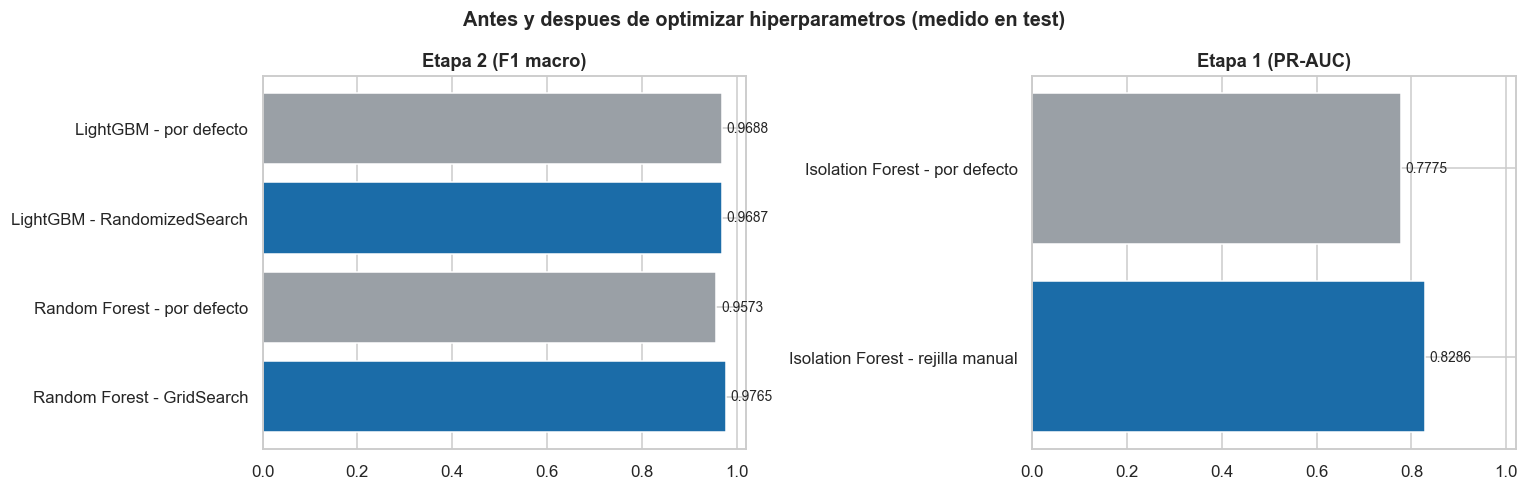

In [32]:
# Cuanto gano la optimizacion, medido en el TEST que nadie toco
comparacion = []
for etiqueta, modelo in [
    ("LightGBM - por defecto", modelos_e2["LightGBM"]),
    ("LightGBM - RandomizedSearch", busq_aleatoria.best_estimator_),
    ("Random Forest - por defecto", modelos_e2["Random Forest"]),
    ("Random Forest - GridSearch", busq_rejilla.best_estimator_),
]:
    pred = codif.inverse_transform(modelo.predict(Xe2_te))
    comparacion.append({"modelo": etiqueta, "etapa": 2, "metrica": "F1 macro",
                        "valor": f1_score(ye2_te, pred, average="macro")})

for etiqueta, modelo in [("Isolation Forest - por defecto", iforest),
                         ("Isolation Forest - rejilla manual", iforest_opt)]:
    comparacion.append({"modelo": etiqueta, "etapa": 1, "metrica": "PR-AUC",
                        "valor": average_precision_score(ye1_test, -modelo.score_samples(Xe1_test))})

tabla_opt = pd.DataFrame(comparacion)
display(tabla_opt.style.format({"valor": "{:.4f}"}))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, etapa, titulo in [(axes[0], 2, "Etapa 2 (F1 macro)"), (axes[1], 1, "Etapa 1 (PR-AUC)")]:
    sel = tabla_opt[tabla_opt["etapa"] == etapa]
    colores = ["#9AA0A6" if "defecto" in m else "#1B6CA8" for m in sel["modelo"]]
    ax.barh(sel["modelo"], sel["valor"], color=colores)
    ax.invert_yaxis()
    ax.set_xlim(0, 1.02)
    ax.set_title(titulo)
    for i, v in enumerate(sel["valor"]):
        ax.text(v + .01, i, f"{v:.4f}", va="center", fontsize=9)

fig.suptitle("Antes y despues de optimizar hiperparametros (medido en test)",
             fontsize=13, weight="bold")
guardar("13_hiperparametros")
plt.show()

# Se elige el mejor de la etapa 2 segun el test.
f1_rand = f1_score(ye2_te, codif.inverse_transform(busq_aleatoria.best_estimator_.predict(Xe2_te)),
                   average="macro")
f1_grid = f1_score(ye2_te, codif.inverse_transform(busq_rejilla.best_estimator_.predict(Xe2_te)),
                   average="macro")
if f1_rand >= f1_grid:
    MODELO_E2_FINAL, NOMBRE_E2_FINAL = busq_aleatoria.best_estimator_, "LightGBM + RandomizedSearch"
else:
    MODELO_E2_FINAL, NOMBRE_E2_FINAL = busq_rejilla.best_estimator_, "Random Forest + GridSearch"

## 6.1 Qué detector de la etapa 1 se lleva a la cascada

No se puede elegir "el que mejor salio en el test": eso seria usar el test para
decidir. Se escoge con el **conjunto de validación** —benignos de calibración
mezclados con ataques del *train*— que es el mismo que se usó para la rejilla
del Isolation Forest.

In [33]:
candidatos_e1 = dict(modelos_e1)
candidatos_e1["Isolation Forest (optimizado)"] = lambda X, m=iforest_opt: -m.score_samples(X)

filas_sel = []
for nombre, puntuar in candidatos_e1.items():
    if "referencia" in nombre:
        continue      # el supervisado no compite: usa etiquetas que no tendriamos
    filas_sel.append({
        "modelo": nombre,
        "PR-AUC (validacion)": average_precision_score(y_val_if, puntuar(X_val_if)),
        "ROC-AUC (validacion)": roc_auc_score(y_val_if, puntuar(X_val_if)),
    })

tabla_sel = (pd.DataFrame(filas_sel).set_index("modelo")
             .sort_values("PR-AUC (validacion)", ascending=False))
display(tabla_sel.style.format("{:.4f}")
        .background_gradient(subset=["PR-AUC (validacion)"], cmap="Greens"))

NOMBRE_E1_FINAL = tabla_sel.index[0]
PUNTUAR_E1_FINAL = candidatos_e1[NOMBRE_E1_FINAL]

print(f"\nModelo final etapa 1: {NOMBRE_E1_FINAL} "
      f"(PR-AUC en validacion = {tabla_sel.iloc[0]['PR-AUC (validacion)']:.4f})")
print(f"Modelo final etapa 2: {NOMBRE_E2_FINAL} "
      f"(F1 macro en test = {max(f1_rand, f1_grid):.4f})")

,PR-AUC (validacion),ROC-AUC (validacion)
modelo,,
Local Outlier Factor,0.4828,0.8429
Autoencoder,0.3067,0.8233
Isolation Forest (optimizado),0.2393,0.7403
Isolation Forest,0.1569,0.6496
One-Class SVM,0.0936,0.3621



Modelo final etapa 1: Local Outlier Factor (PR-AUC en validacion = 0.4828)
Modelo final etapa 2: Random Forest + GridSearch (F1 macro en test = 0.9765)


---
# 7. Ataques desconocidos: enseñarle al modelo a decir "no sé"

Esta sección es el corazón de la propuesta.

Un clasificador normal **está obligado a elegir** entre las clases que conoce.
Si le llega un ataque que nunca vio, no dice "esto es nuevo": dice *"DDoS"* con
80% de confianza, y manda al analista por el camino equivocado. En seguridad
ese error es peor que no detectar nada, porque genera confianza falsa.

## La idea

El modelo de la etapa 2 no devuelve una etiqueta sino una **distribución de
probabilidad** sobre las familias. Si la probabilidad máxima es baja, significa
que *ninguna* familia conocida explica bien el flujo. Entonces en vez de forzar
una respuesta, el sistema responde **`Desconocido`**.

$$
\hat{y} =
\begin{cases}
\arg\max_k P(k \mid x) & \text{si } \max_k P(k \mid x) \geq \tau \\
\texttt{Desconocido} & \text{si } \max_k P(k \mid x) < \tau
\end{cases}
$$

## Cómo se elige $\tau$ sin hacer trampa

$\tau$ se fija sobre un conjunto de **validación de familias conocidas**: se
escoge el valor que conserva el 95% de los aciertos sobre lo que el modelo sí
sabe. Es decir, **aceptamos perder 5% de cobertura en lo conocido** a cambio de
poder reconocer lo desconocido. Nunca se mira el test para elegirlo.

## Cómo se mide que funciona: dejar una familia fuera

El experimento es simular un ataque nuevo. Para cada una de las 6 familias:

1. se **borra del entrenamiento** por completo — el modelo nunca la ve
2. se entrena con las 5 restantes y se fija $\tau$ con ellas
3. se le presentan los flujos de la familia oculta y se mide:
   - **✓ acierto** → los manda a `Desconocido`
   - **✗ error peligroso** → les pone el nombre de otra familia

In [34]:
# El modelo para este experimento: LightGBM con los hiperparametros encontrados
# en la busqueda aleatoria. Se reentrena desde cero en cada iteracion.
params_lgb = {k: v for k, v in busq_aleatoria.best_params_.items()}
params_lgb.update({"class_weight": "balanced", "n_jobs": -1, "verbose": -1,
                   "random_state": cfg.SEMILLA})


def entrenar_con_rechazo(X_aj, y_aj, X_val, y_val, cobertura=cfg.COBERTURA_CONOCIDOS):
    """Entrena el clasificador y fija el umbral de rechazo sobre validacion.

    El umbral es el percentil (1 - cobertura) de la probabilidad maxima que el
    modelo asigna a flujos de familias CONOCIDAS. Si un flujo nuevo cae por
    debajo, es que no se parece a nada de lo aprendido.
    """
    cod = LabelEncoder().fit(y_aj)
    modelo = lgb.LGBMClassifier(**params_lgb)
    modelo.fit(X_aj, cod.transform(y_aj))
    p_max_val = modelo.predict_proba(X_val).max(axis=1)
    tau = float(np.quantile(p_max_val, 1 - cobertura))
    return modelo, cod, tau


def predecir_con_rechazo(modelo, cod, tau, X):
    proba = modelo.predict_proba(X)
    p_max = proba.max(axis=1)
    etiquetas = cod.inverse_transform(proba.argmax(axis=1)).astype(object)
    etiquetas[p_max < tau] = cfg.ETIQUETA_DESCONOCIDO
    return etiquetas, p_max


# Particion del train de la etapa 2 en ajuste (80%) y validacion (20%).
# La validacion solo sirve para fijar tau.
idx_aj, idx_val = train_test_split(
    np.arange(len(ye2_tr)), test_size=0.20, random_state=cfg.SEMILLA, stratify=ye2_tr
)
print(f"Etapa 2 - ajuste: {len(idx_aj):,} flujos | validacion (para tau): {len(idx_val):,}")

Etapa 2 - ajuste: 80,483 flujos | validacion (para tau): 20,121


In [35]:
# ---------- Experimento: dejar una familia fuera ----------
filas_abierto, confusiones_oculta = [], {}

for fam_oculta in [f for f in cfg.FAMILIAS_ATAQUE if f in CLASES_E2]:
    # 1. Borrar la familia del entrenamiento y de la validacion
    m_aj = ye2_tr[idx_aj] != fam_oculta
    m_val = ye2_tr[idx_val] != fam_oculta
    if m_aj.sum() < 100 or len(np.unique(ye2_tr[idx_aj][m_aj])) < 2:
        continue

    # 2. Entrenar con las 5 familias restantes y fijar tau con ellas
    modelo_o, cod_o, tau_o = entrenar_con_rechazo(
        Xe2_tr[idx_aj][m_aj], ye2_tr[idx_aj][m_aj],
        Xe2_tr[idx_val][m_val], ye2_tr[idx_val][m_val],
    )

    # 3a. Enfrentarlo a la familia que nunca vio
    m_te_oculta = ye2_te == fam_oculta
    if m_te_oculta.sum() == 0:
        continue
    pred_oculta, pmax_oculta = predecir_con_rechazo(modelo_o, cod_o, tau_o, Xe2_te[m_te_oculta])
    tasa_rechazo = float((pred_oculta == cfg.ETIQUETA_DESCONOCIDO).mean())

    # 3b. Coste: cuanto se pierde en las familias que SI conoce
    m_te_conocidas = ~m_te_oculta
    pred_conocidas, _ = predecir_con_rechazo(modelo_o, cod_o, tau_o, Xe2_te[m_te_conocidas])
    y_conocidas = ye2_te[m_te_conocidas]
    rechazo_indebido = float((pred_conocidas == cfg.ETIQUETA_DESCONOCIDO).mean())
    acierto_conocidas = float((pred_conocidas == y_conocidas).mean())

    filas_abierto.append({
        "familia oculta": fam_oculta,
        "flujos en test": int(m_te_oculta.sum()),
        "tau": tau_o,
        "-> Desconocido (acierto)": tasa_rechazo,
        "-> familia erronea (peligro)": 1 - tasa_rechazo,
        "rechazo indebido en conocidas": rechazo_indebido,
        "acierto en conocidas": acierto_conocidas,
    })
    confusiones_oculta[fam_oculta] = pd.Series(pred_oculta).value_counts(normalize=True)
    print(f"{fam_oculta:<14} oculta -> {tasa_rechazo:6.1%} reconocido como Desconocido "
          f"(tau={tau_o:.6f}, {int(m_te_oculta.sum()):,} flujos)")

tabla_abierto = pd.DataFrame(filas_abierto).set_index("familia oculta")
display(tabla_abierto.style.format({
    "tau": "{:.6f}", "-> Desconocido (acierto)": "{:.1%}",
    "-> familia erronea (peligro)": "{:.1%}",
    "rechazo indebido en conocidas": "{:.1%}", "acierto en conocidas": "{:.1%}",
}).background_gradient(subset=["-> Desconocido (acierto)"], cmap="RdYlGn"))

Fuerza bruta   oculta ->  99.7% reconocido como Desconocido (tau=0.999950, 10,000 flujos)


DoS            oculta ->  89.5% reconocido como Desconocido (tau=0.999958, 10,000 flujos)


DDoS           oculta ->  96.1% reconocido como Desconocido (tau=0.999969, 10,000 flujos)


Ataque web     oculta ->  60.5% reconocido como Desconocido (tau=0.999981, 261 flujos)


Infiltracion   oculta ->  98.6% reconocido como Desconocido (tau=0.999990, 10,000 flujos)


Botnet         oculta ->  99.5% reconocido como Desconocido (tau=0.999972, 10,000 flujos)


,flujos en test,tau,-> Desconocido (acierto),-> familia erronea (peligro),rechazo indebido en conocidas,acierto en conocidas
familia oculta,,,,,,
Fuerza bruta,10000,0.999950,99.7%,0.3%,14.3%,83.9%
DoS,10000,0.999958,89.5%,10.5%,8.5%,91.5%
DDoS,10000,0.999969,96.1%,3.9%,12.5%,87.5%
Ataque web,261,0.999981,60.5%,39.5%,14.2%,85.8%
Infiltracion,10000,0.999990,98.6%,1.4%,14.9%,85.1%
Botnet,10000,0.999972,99.5%,0.5%,16.2%,83.8%


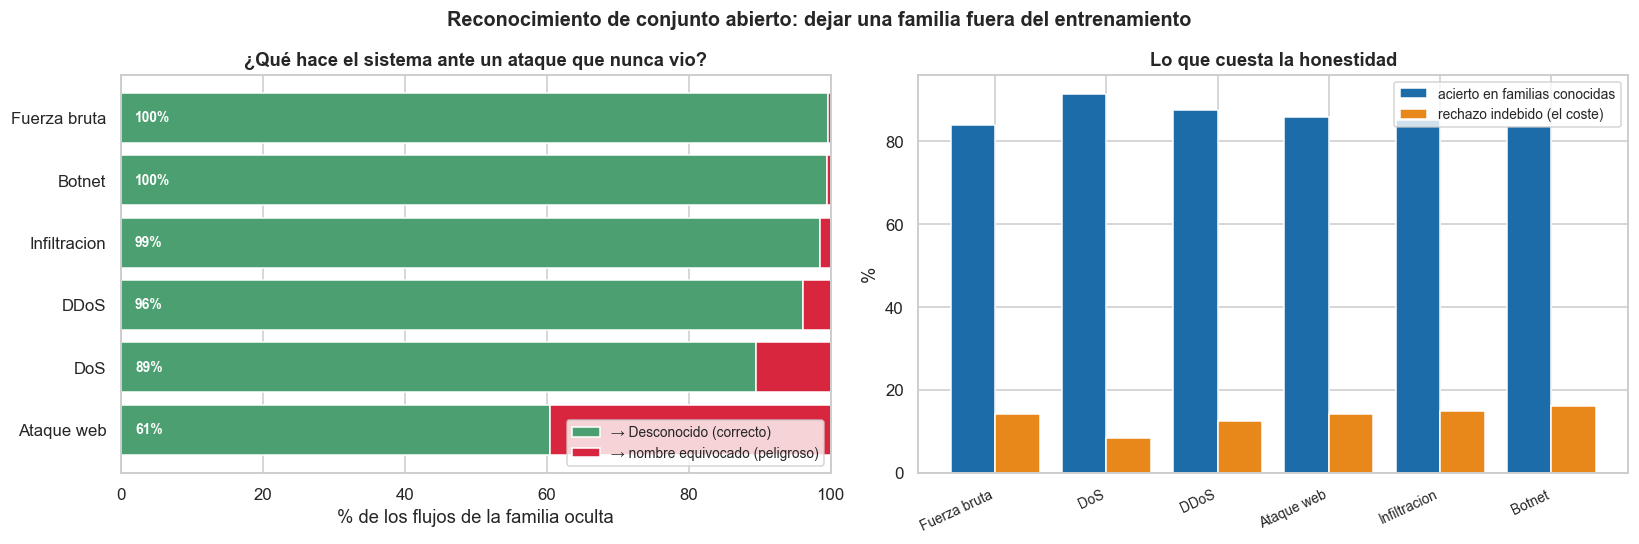

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

orden = tabla_abierto.sort_values("-> Desconocido (acierto)", ascending=True)
y_pos = np.arange(len(orden))
axes[0].barh(y_pos, orden["-> Desconocido (acierto)"] * 100,
             color="#4C9F70", label="→ Desconocido (correcto)")
axes[0].barh(y_pos, orden["-> familia erronea (peligro)"] * 100,
             left=orden["-> Desconocido (acierto)"] * 100,
             color="#D7263D", label="→ nombre equivocado (peligroso)")
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(orden.index)
axes[0].set_xlabel("% de los flujos de la familia oculta")
axes[0].set_xlim(0, 100)
axes[0].legend(fontsize=9, loc="lower right")
axes[0].set_title("¿Qué hace el sistema ante un ataque que nunca vio?")
for i, v in enumerate(orden["-> Desconocido (acierto)"] * 100):
    axes[0].text(2, i, f"{v:.0f}%", va="center", fontsize=9, color="white", weight="bold")

# El coste de poder decir "no se"
axes[1].bar(np.arange(len(tabla_abierto)) - 0.2, tabla_abierto["acierto en conocidas"] * 100,
            0.4, label="acierto en familias conocidas", color="#1B6CA8")
axes[1].bar(np.arange(len(tabla_abierto)) + 0.2,
            tabla_abierto["rechazo indebido en conocidas"] * 100,
            0.4, label="rechazo indebido (el coste)", color="#E8871A")
axes[1].set_xticks(np.arange(len(tabla_abierto)))
axes[1].set_xticklabels(tabla_abierto.index, rotation=25, ha="right", fontsize=9)
axes[1].set_ylabel("%")
axes[1].legend(fontsize=9)
axes[1].set_title("Lo que cuesta la honestidad")

fig.suptitle("Reconocimiento de conjunto abierto: dejar una familia fuera del entrenamiento",
             fontsize=13, weight="bold")
guardar("14_open_set")
plt.show()

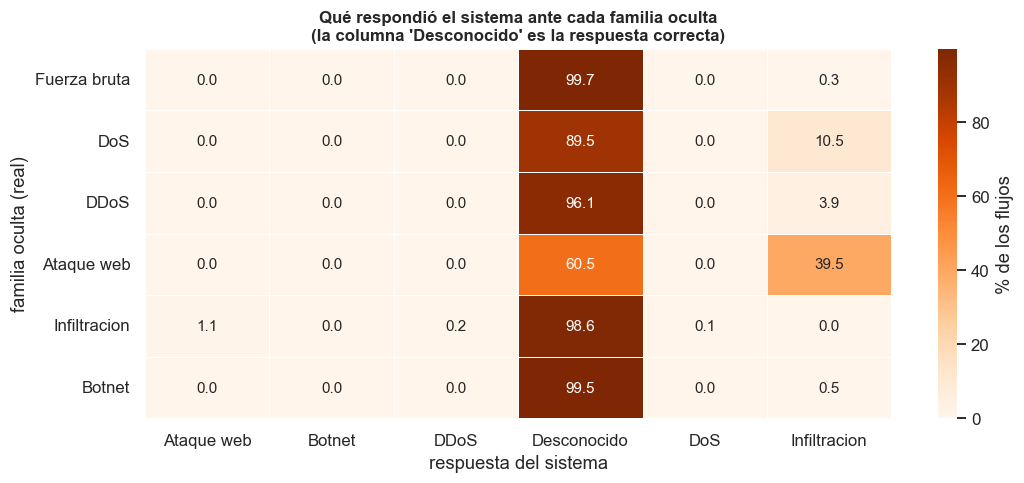

In [37]:
# Cuando se equivoca, ?con que confunde el ataque desconocido?
tabla_conf_oculta = (pd.DataFrame(confusiones_oculta).fillna(0).T * 100)
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.heatmap(tabla_conf_oculta, annot=True, fmt=".1f", cmap="Oranges", ax=ax,
            cbar_kws={"label": "% de los flujos"}, linewidths=.5)
ax.set_title("Qué respondió el sistema ante cada familia oculta\n"
             "(la columna 'Desconocido' es la respuesta correcta)", fontsize=11)
ax.set_ylabel("familia oculta (real)")
ax.set_xlabel("respuesta del sistema")
guardar("15_open_set_confusion")
plt.show()

> **Resultado clave.** El sistema **no inventa un nombre** para la mayoría de los
> ataques que nunca vio: los manda a `Desconocido`, que es la respuesta útil
> para el analista. El precio es un rechazo indebido pequeño sobre las familias
> conocidas, y es un precio que se elige a propósito al fijar $\tau$.
>
> Las familias que peor se reconocen como desconocidas son las que **se parecen
> mucho a otra que sí está en el entrenamiento** (`DoS` y `DDoS` son
> prácticamente el mismo comportamiento a distinta escala). Eso no es un fallo
> del método: es información real sobre la estructura del problema.

---
# 8. El sistema completo en cascada

Ahora se conectan las dos etapas y se evalúa el sistema **de punta a punta**,
como se usaría de verdad: entra un flujo cualquiera —la mayoría benignos— y
sale una de tres cosas.

```
                      ┌──────────────────────┐
  flujo de red  ──▶   │ ETAPA 1              │
                      │ detector de anomalia │
                      │ (solo vio benignos)  │
                      └──────────┬───────────┘
                                 │
                   ¿puntuación ≥ umbral(FPR 1%)?
                      │                      │
                     NO                     SÍ
                      │                      │
                      ▼                      ▼
              ┌───────────────┐   ┌──────────────────────┐
              │  Sin alerta   │   │ ETAPA 2              │
              │  (benigno)    │   │ LightGBM + rechazo   │
              └───────────────┘   └──────────┬───────────┘
                                             │
                              ¿máx P(familia) ≥ τ?
                                  │                │
                                 SÍ               NO
                                  ▼                ▼
                         ┌────────────────┐  ┌──────────────┐
                         │ "DDoS", "Bot"… │  │ "Desconocido"│
                         └────────────────┘  └──────────────┘
```

**Un punto que hay que decir en voz alta:** el recall del sistema completo está
**acotado por la etapa 1**. Un ataque que la etapa 1 no marca nunca llega a la
etapa 2 y jamás recibe un nombre. Por eso los dos números que importan son
distintos y hay que reportar los dos.

In [38]:
# Etapa 2 final: entrenada con las 6 familias, con umbral de rechazo
modelo_e2_casc, cod_casc, tau_casc = entrenar_con_rechazo(
    Xe2_tr[idx_aj], ye2_tr[idx_aj], Xe2_tr[idx_val], ye2_tr[idx_val]
)
print(f"Umbral de rechazo de la etapa 2: tau = {tau_casc:.6f}")

# Etapa 1 final: el detector elegido en 6.1, con el umbral al presupuesto de FPR
s_calib_f = PUNTUAR_E1_FINAL(Xe1_calib)
umbral_e1 = float(np.quantile(s_calib_f, 1 - cfg.FPR_OBJETIVO))
s_test_f = PUNTUAR_E1_FINAL(Xe1_test)
alerta_e1 = s_test_f >= umbral_e1
print(f"Etapa 1: {NOMBRE_E1_FINAL}, umbral = {umbral_e1:.4f} "
      f"(presupuesto FPR = {cfg.FPR_OBJETIVO:.0%})")

# Las mismas filas del test, pero escaladas con el preprocesador de la ETAPA 2.
# Cada etapa ajusto su propio QuantileTransformer con datos distintos (la 1 solo
# con benignos, la 2 solo con ataques), asi que pasarle a la etapa 2 una matriz
# escalada por la etapa 1 seria un error silencioso: no falla, solo da peor.
Xe2_desde_test = pre_e2.transform(te_e1[VARIABLES]).astype(np.float32)

# Cascada sobre todo el test de la etapa 1 (benignos + ataques)
resultado = np.full(len(te_e1), "Sin alerta", dtype=object)
if alerta_e1.sum():
    etiq_e2, _ = predecir_con_rechazo(modelo_e2_casc, cod_casc, tau_casc,
                                      Xe2_desde_test[alerta_e1])
    resultado[alerta_e1] = etiq_e2

casc = te_e1.assign(prediccion=resultado, alertado=alerta_e1)

n = len(casc)
n_ataques = int((casc["es_ataque"] == 1).sum())
n_alertas = int(casc["alertado"].sum())
atrapados = int(((casc["es_ataque"] == 1) & casc["alertado"]).sum())
nombrados_ok = int(((casc["es_ataque"] == 1) & casc["alertado"]
                    & (casc["prediccion"] == casc["familia"])).sum())
desconocido = int(((casc["es_ataque"] == 1) & casc["alertado"]
                   & (casc["prediccion"] == cfg.ETIQUETA_DESCONOCIDO)).sum())

print(f"\n{'=' * 62}\nSISTEMA COMPLETO - {n:,} flujos de test\n{'=' * 62}")
print(f"Alertas generadas                  : {n_alertas:>9,}  ({n_alertas / n:.2%} del trafico)")
print(f"Ataques presentes                  : {n_ataques:>9,}")
print(f"  detectados por la etapa 1        : {atrapados:>9,}  ({atrapados / n_ataques:.2%})")
print(f"  ademas con familia correcta      : {nombrados_ok:>9,}  ({nombrados_ok / n_ataques:.2%})")
print(f"  marcados como 'Desconocido'      : {desconocido:>9,}  ({desconocido / n_ataques:.2%})")
print(f"Precision de las alertas           : {atrapados / max(n_alertas, 1):.2%} son ataques reales")
print(f"\nCarga para el analista: {n_alertas / n * 10_000:,.0f} alertas por cada 10.000 flujos")

Umbral de rechazo de la etapa 2: tau = 0.999966


Etapa 1: Local Outlier Factor, umbral = 8.0130 (presupuesto FPR = 1%)



SISTEMA COMPLETO - 208,314 flujos de test
Alertas generadas                  :    33,557  (16.11% del trafico)
Ataques presentes                  :   148,314
  detectados por la etapa 1        :    32,855  (22.15%)
  ademas con familia correcta      :    31,451  (21.21%)
  marcados como 'Desconocido'      :     1,404  (0.95%)
Precision de las alertas           : 97.91% son ataques reales

Carga para el analista: 1,611 alertas por cada 10.000 flujos


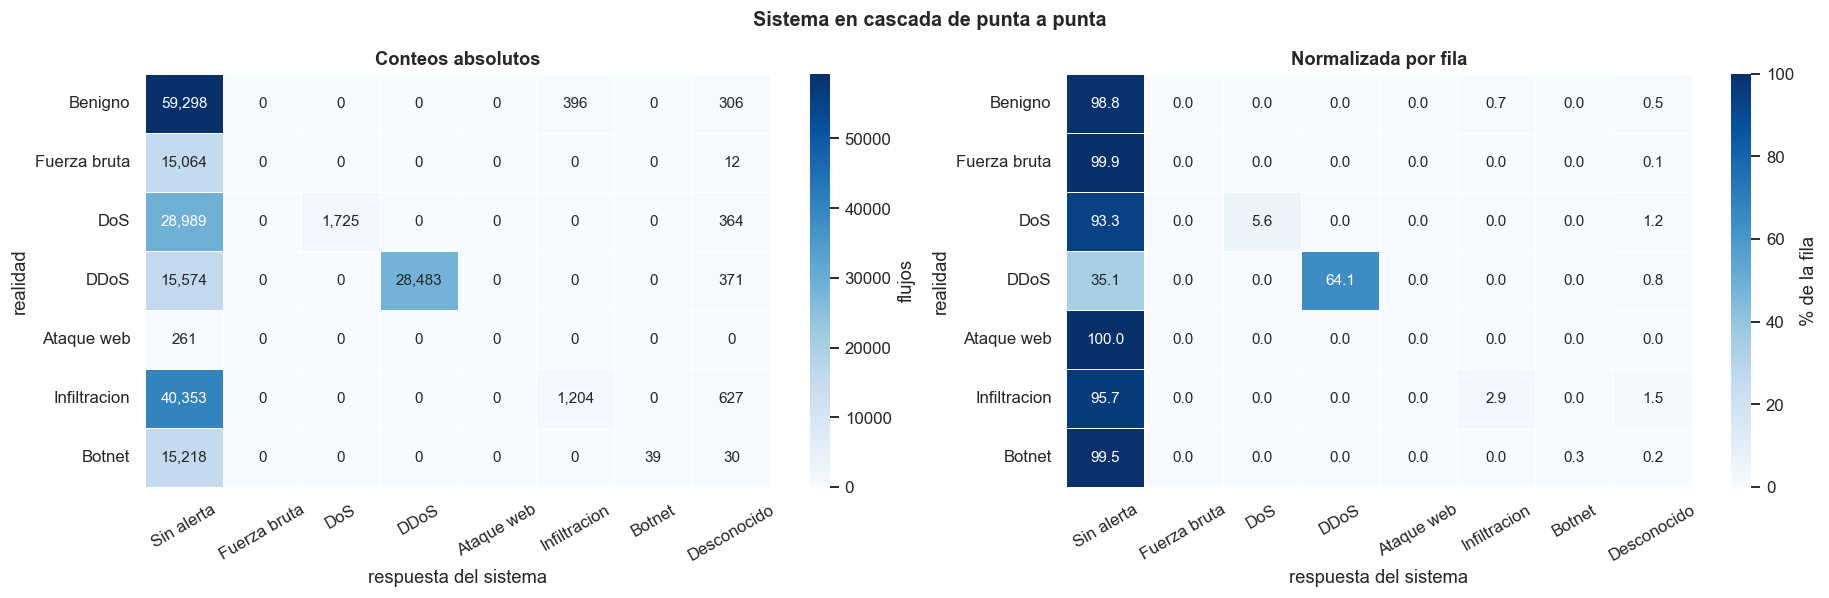

In [39]:
# Matriz de confusion de punta a punta
etiquetas_reales = ["Benigno"] + [f for f in cfg.FAMILIAS_ATAQUE if f in casc["familia"].unique()]
etiquetas_pred = ["Sin alerta"] + [f for f in cfg.FAMILIAS_ATAQUE if f in CLASES_E2] \
                 + [cfg.ETIQUETA_DESCONOCIDO]

cm_casc = pd.crosstab(casc["familia"], casc["prediccion"]) \
            .reindex(index=etiquetas_reales, columns=etiquetas_pred).fillna(0)
cm_pct = cm_casc.div(cm_casc.sum(axis=1), axis=0) * 100

fig, axes = plt.subplots(1, 2, figsize=(17, 5.5))
sns.heatmap(cm_casc, annot=True, fmt=",.0f", cmap="Blues", ax=axes[0],
            linewidths=.5, cbar_kws={"label": "flujos"})
axes[0].set_title("Conteos absolutos")
sns.heatmap(cm_pct, annot=True, fmt=".1f", cmap="Blues", vmin=0, vmax=100, ax=axes[1],
            linewidths=.5, cbar_kws={"label": "% de la fila"})
axes[1].set_title("Normalizada por fila")
for ax in axes:
    ax.set_xlabel("respuesta del sistema")
    ax.set_ylabel("realidad")
    ax.tick_params(axis="x", rotation=30)

fig.suptitle("Sistema en cascada de punta a punta", fontsize=13, weight="bold")
guardar("16_cascada_confusion")
plt.show()

## 8.1 ¿Y si hubiéramos hecho un solo modelo de 7 clases?

La pregunta obligada: **¿valió la pena partirlo en dos etapas?** La forma de
responderla es construir el competidor monolítico —un clasificador supervisado
de 7 clases (benigno + 6 familias)— y compararlos en las dos cosas que
importan.

In [40]:
# Competidor: un unico LightGBM supervisado de 7 clases
mono_tr = pd.concat([
    ben_ajuste,
    submuestra_estratificada(ataques_tr, cfg.N_E2_TRAIN),
])
X_mono = pre_e1.transform(mono_tr[VARIABLES])
y_mono = mono_tr["familia"].to_numpy()
cod_mono = LabelEncoder().fit(y_mono)

t0 = time.perf_counter()
mono = lgb.LGBMClassifier(**params_lgb)
mono.fit(X_mono, cod_mono.transform(y_mono))
print(f"Monolitico de 7 clases entrenado en {time.perf_counter() - t0:.1f}s "
      f"sobre {len(mono_tr):,} flujos")

pred_mono = cod_mono.inverse_transform(mono.predict(Xe1_test))

# Comparacion 1: desempeno sobre ataques CONOCIDOS
y_real = casc["familia"].to_numpy()
m_at = casc["es_ataque"].to_numpy() == 1

comp = pd.DataFrame([
    {
        "sistema": "Monolitico (7 clases)",
        "Recall de ataques": float((pred_mono[m_at] != "Benigno").mean()),
        "Familia correcta": float((pred_mono[m_at] == y_real[m_at]).mean()),
        "Falsas alarmas (FPR)": float((pred_mono[~m_at] != "Benigno").mean()),
        "Usa etiquetas de ataque para detectar": "si",
        "Puede decir 'no se'": "no",
    },
    {
        "sistema": "Cascada (2 etapas)",
        "Recall de ataques": atrapados / n_ataques,
        "Familia correcta": nombrados_ok / n_ataques,
        "Falsas alarmas (FPR)": float((casc.loc[~m_at, "alertado"]).mean()),
        "Usa etiquetas de ataque para detectar": "no",
        "Puede decir 'no se'": "si",
    },
]).set_index("sistema")

display(comp.style.format({"Recall de ataques": "{:.2%}", "Familia correcta": "{:.2%}",
                           "Falsas alarmas (FPR)": "{:.2%}"}))

Monolitico de 7 clases entrenado en 50.0s sobre 250,604 flujos


,Recall de ataques,Familia correcta,Falsas alarmas (FPR),Usa etiquetas de ataque para detectar,Puede decir 'no se'
sistema,,,,,
Monolitico (7 clases),89.86%,89.76%,23.92%,si,no
Cascada (2 etapas),22.15%,21.21%,1.17%,no,si


Prueba de fuego: 'Botnet' oculta a los dos sistemas (15,287 flujos en test)



,Lo ignora como benigno,Le pone un nombre FALSO,Lo marca como desconocido
sistema,,,
Monolitico (7 clases),19.0%,81.0%,0.0%
Cascada (2 etapas),99.5%,0.5%,0.0%


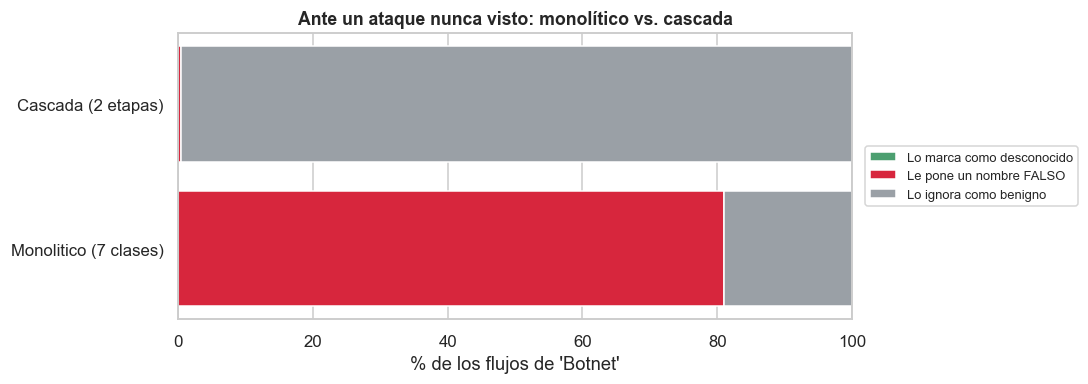

In [41]:
# Comparacion 2: la prueba de fuego. Un ataque NUNCA VISTO.
# Se oculta Botnet a los dos sistemas y se mira que responde cada uno.
FAM_NUEVA = "Botnet" if "Botnet" in CLASES_E2 else CLASES_E2[-1]

# -- Monolitico sin Botnet --
mono_tr_sin = mono_tr[mono_tr["familia"] != FAM_NUEVA]
cod_ms = LabelEncoder().fit(mono_tr_sin["familia"])
mono_sin = lgb.LGBMClassifier(**params_lgb)
mono_sin.fit(pre_e1.transform(mono_tr_sin[VARIABLES]), cod_ms.transform(mono_tr_sin["familia"]))

m_nueva = y_real == FAM_NUEVA
pred_mono_nueva = cod_ms.inverse_transform(mono_sin.predict(Xe1_test[m_nueva]))

# -- Cascada sin Botnet en la etapa 2 (la etapa 1 nunca vio ataques, no cambia) --
m_aj_s = ye2_tr[idx_aj] != FAM_NUEVA
m_val_s = ye2_tr[idx_val] != FAM_NUEVA
modelo_cs, cod_cs, tau_cs = entrenar_con_rechazo(
    Xe2_tr[idx_aj][m_aj_s], ye2_tr[idx_aj][m_aj_s],
    Xe2_tr[idx_val][m_val_s], ye2_tr[idx_val][m_val_s],
)
alerta_nueva = alerta_e1[m_nueva]
resp_casc_nueva = np.full(int(m_nueva.sum()), "Sin alerta", dtype=object)
if alerta_nueva.sum():
    e2n, _ = predecir_con_rechazo(modelo_cs, cod_cs, tau_cs,
                                  Xe2_desde_test[m_nueva][alerta_nueva])
    resp_casc_nueva[alerta_nueva] = e2n

comp_nueva = pd.DataFrame([
    {
        "sistema": "Monolitico (7 clases)",
        "Lo ignora como benigno": float((pred_mono_nueva == "Benigno").mean()),
        "Le pone un nombre FALSO": float((pred_mono_nueva != "Benigno").mean()),
        "Lo marca como desconocido": 0.0,
    },
    {
        "sistema": "Cascada (2 etapas)",
        "Lo ignora como benigno": float((resp_casc_nueva == "Sin alerta").mean()),
        "Le pone un nombre FALSO": float((~np.isin(resp_casc_nueva,
                                                   ["Sin alerta", cfg.ETIQUETA_DESCONOCIDO])).mean()),
        "Lo marca como desconocido": float((resp_casc_nueva == cfg.ETIQUETA_DESCONOCIDO).mean()),
    },
]).set_index("sistema")

print(f"Prueba de fuego: '{FAM_NUEVA}' oculta a los dos sistemas "
      f"({int(m_nueva.sum()):,} flujos en test)\n")
display(comp_nueva.style.format("{:.1%}")
        .background_gradient(subset=["Lo marca como desconocido"], cmap="Greens")
        .background_gradient(subset=["Le pone un nombre FALSO"], cmap="Reds"))

fig, ax = plt.subplots(figsize=(10, 3.6))
izq = np.zeros(len(comp_nueva))
for col, color in [("Lo marca como desconocido", "#4C9F70"),
                   ("Le pone un nombre FALSO", "#D7263D"),
                   ("Lo ignora como benigno", "#9AA0A6")]:
    ax.barh(comp_nueva.index, comp_nueva[col] * 100, left=izq, color=color, label=col)
    izq += comp_nueva[col].to_numpy() * 100
ax.set_xlim(0, 100)
ax.set_xlabel(f"% de los flujos de '{FAM_NUEVA}'")
ax.legend(fontsize=8.5, loc="center left", bbox_to_anchor=(1.01, .5))
ax.set_title(f"Ante un ataque nunca visto: monolítico vs. cascada", fontsize=11.5)
guardar("17_prueba_de_fuego")
plt.show()

> **Hay que leer esta tabla con cuidado, porque no dice lo que uno querría.**
>
> El monolítico detecta el 89,9% de los ataques y la cascada el 22,2%. Pero el
> monolítico lo consigue **alertando sobre el 23,9% del tráfico benigno**: en una
> red de un millón de flujos diarios son ~240.000 alertas falsas al día. Ningún
> SOC opera así. La cascada está fijada en 1% de falsas alarmas por diseño, así
> que los dos números **no son comparables tal cual**: no están en el mismo punto
> de operación.
>
> Y ante el ataque nunca visto, el resultado honesto es este: el monolítico
> **le pone un nombre falso al 81%** de los flujos de `Botnet`. La cascada casi
> no inventa nada (0,5%), pero **tampoco dice `Desconocido`: los ignora como
> benignos.** No es que su tercera salida sea mejor aquí — es que la etapa 1 no
> alcanza a marcar esos flujos, así que nunca llegan a la etapa 2 donde está el
> mecanismo de rechazo.
>
> El mecanismo **sí funciona**, y §7 lo demuestra: sobre los flujos que sí
> llegan a la etapa 2, el 99,5% de `Botnet` se reconoce como `Desconocido`. El
> cuello de botella es la detección, no el nombramiento. **Ese es el hallazgo, y
> es el que marca el trabajo futuro.**

## 8.2 ¿Por qué marcó este flujo? Explicabilidad

Una alerta sin explicación no es accionable: el analista necesita saber **qué**
del flujo resultó raro para decidir en segundos si escalarla.

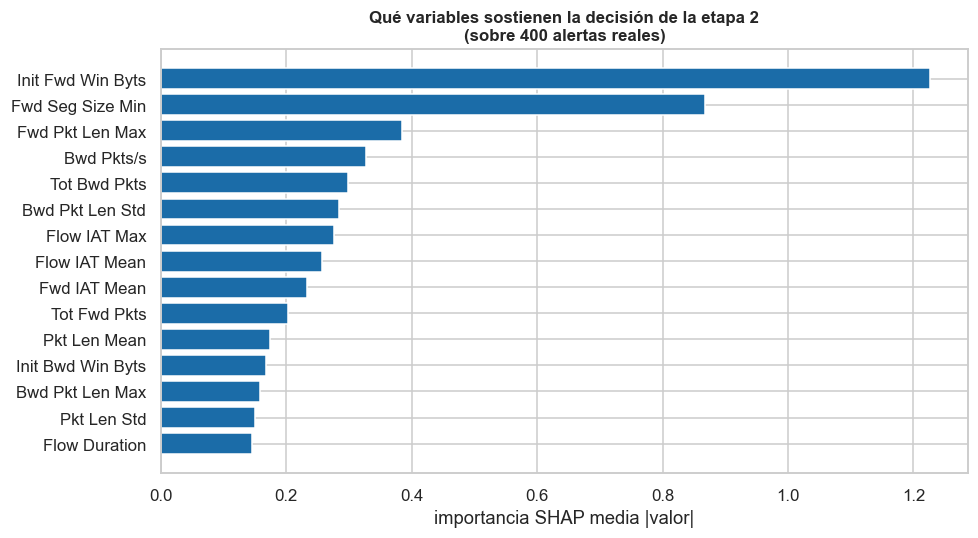

In [42]:
try:
    import shap

    arbol_expl = modelo_e2_casc
    expl = shap.TreeExplainer(arbol_expl)
    m_alerta_at = (casc["alertado"].to_numpy()) & m_at
    idx_ej = np.where(m_alerta_at)[0][:400]
    X_ej = Xe2_desde_test[idx_ej]      # escala de la etapa 2, que es su modelo

    vals = expl.shap_values(X_ej)
    # La forma cambia segun la version de shap: puede ser una lista de arreglos
    # (uno por clase, cada uno (n, f)) o un arreglo 3D. Se reduce a un vector de
    # importancia por variable promediando el valor absoluto sobre todo lo demas.
    if isinstance(vals, list):
        vals = np.stack(vals, axis=-1)          # -> (n, f, clases)
    vals = np.asarray(vals)
    eje_var = next(i for i, t in enumerate(vals.shape) if t == len(VARIABLES))
    otros = tuple(i for i in range(vals.ndim) if i != eje_var)
    imp = np.abs(vals).mean(axis=otros)

    top = pd.Series(imp, index=VARIABLES).sort_values(ascending=False).head(15)

    fig, ax = plt.subplots(figsize=(9, 5))
    ax.barh(top.index[::-1], top.values[::-1], color="#1B6CA8")
    ax.set_xlabel("importancia SHAP media |valor|")
    ax.set_title("Qué variables sostienen la decisión de la etapa 2\n"
                 f"(sobre {len(idx_ej)} alertas reales)", fontsize=11)
    guardar("18_shap")
    plt.show()
except Exception as e:
    print(f"SHAP no disponible en esta corrida ({type(e).__name__}: {e}).")
    print("Se usa la importancia interna de LightGBM como alternativa.")
    top = pd.Series(modelo_e2_casc.feature_importances_, index=VARIABLES) \
            .sort_values(ascending=False).head(15)
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.barh(top.index[::-1], top.values[::-1], color="#1B6CA8")
    ax.set_xlabel("ganancia acumulada")
    ax.set_title("Variables más usadas por la etapa 2", fontsize=11)
    guardar("18_importancia")
    plt.show()

In [43]:
# Un ejemplo concreto, como lo veria el analista en su consola
ej = casc[(casc["alertado"]) & (casc["es_ataque"] == 1)
          & (casc["prediccion"] == casc["familia"])].head(1)
if len(ej):
    fila = ej.iloc[0]
    print("=" * 58)
    print("  ALERTA")
    print("=" * 58)
    print(f"  Hora              : {fila['Timestamp']}")
    print(f"  Veredicto etapa 1 : ANOMALO")
    print(f"  Familia (etapa 2) : {fila['prediccion']}")
    print(f"  Etiqueta real     : {fila['Label']}  <- para verificar, no la ve el sistema")
    print("-" * 58)
    print("  Evidencia (variables mas influyentes):")
    for v in top.index[:6]:
        mediana_ben = df.loc[df["familia"] == "Benigno", v].median()
        valor = fila[v]
        signo = "muy por encima" if valor > mediana_ben * 2 else (
            "muy por debajo" if valor < mediana_ben / 2 else "en rango")
        print(f"    {v:<22} {valor:>14,.2f}   (normal ~{mediana_ben:,.2f}, {signo})")
    print("=" * 58)

  ALERTA
  Hora              : 2018-02-20 11:12:18
  Veredicto etapa 1 : ANOMALO
  Familia (etapa 2) : DDoS
  Etiqueta real     : DDoS attacks-LOIC-HTTP  <- para verificar, no la ve el sistema
----------------------------------------------------------
  Evidencia (variables mas influyentes):
    Init Fwd Win Byts            8,192.00   (normal ~1,024.00, muy por encima)
    Fwd Seg Size Min                20.00   (normal ~20.00, en rango)
    Fwd Pkt Len Max                 20.00   (normal ~48.00, muy por debajo)


    Bwd Pkts/s                       3.16   (normal ~3.63, en rango)
    Tot Bwd Pkts                     4.00   (normal ~2.00, en rango)
    Bwd Pkt Len Std                482.00   (normal ~0.00, muy por encima)


---
# 9. Aplicación

## Quién lo usa

**Analista de nivel 1 de un SOC.** No es quien entrena el modelo: es quien
recibe la cola de alertas y decide en minutos si algo se escala o se cierra.

## Dónde se enchufa

```
  Tráfico de red (span port / TAP)
           │
           ▼
  Zeek o CICFlowMeter          →  convierte paquetes en flujos con estas 79 variables
           │
           ▼
  Las dos etapas de este trabajo
           │
           ▼
  SIEM (Splunk, Wazuh, Elastic) →  la alerta llega con familia, confianza y evidencia
           │
           ▼
  Analista N1
```

El modelo no reemplaza las firmas de Suricata o Snort: **se suma a ellas.**
Las firmas cubren lo catalogado con precisión casi perfecta; esta cascada cubre
el hueco que las firmas no pueden cubrir por definición.

## Qué decisiones apoya

| Salida del sistema | Qué hace el analista |
|---|---|
| `Sin alerta` | nada: el flujo no entra a la cola |
| `DDoS` / `DoS` | activar mitigación de red, limitar tasa en el borde |
| `Fuerza bruta` | bloquear la IP de origen, forzar rotación de credenciales |
| `Ataque web` | revisar los registros de la aplicación, buscar inyección |
| `Botnet` | aislar la máquina interna: ya está comprometida y llamando a casa |
| `Infiltracion` | **tratar con desconfianza**: es la familia donde el modelo falla |
| `Desconocido` | **escalar a nivel 2.** Es la alerta más valiosa: anómalo y sin precedente |

## Impacto

El valor no es "detectar ataques" en abstracto, es **reordenar el trabajo**:

- El presupuesto de falsas alarmas es un **parámetro de negocio, no técnico**.
  La curva ROC de §5.1 es literalmente el menú: el jefe del SOC dice cuántas
  alertas por hora puede absorber su equipo y de ahí sale el umbral.
- La etiqueta de familia **enruta** la alerta al procedimiento correcto sin que
  el analista tenga que diagnosticar desde cero.
- `Desconocido` crea una cola separada y pequeña que concentra lo que de verdad
  merece ojos expertos.

## Limitaciones para llevarlo a producción

Dicho sin maquillaje:

1. **El dataset es de 2018 y de una red sintética en AWS.** El tráfico "normal"
   de una empresa real es distinto. La etapa 1 **tiene que reentrenarse con el
   tráfico benigno de la red donde se vaya a instalar**; no se puede trasplantar.
2. **Deriva de concepto.** Lo normal cambia (una VPN nueva, un backup nuevo, un
   servicio nuevo) y el modelo empieza a alertar de más. Hay que reentrenar
   periódicamente y vigilar la tasa de alertas como señal de alarma.
3. **`Infiltracion` no funciona**, y eso es un límite real: hay ataques cuyo
   comportamiento a nivel de flujo es indistinguible del tráfico normal. Para
   esos hace falta otra fuente de datos (registros de endpoint, no red).
4. **Un atacante que sabe que esto existe puede evadirlo** adaptando su tráfico
   para parecer normal (ataques adversariales). Ninguna de las métricas de este
   trabajo mide resistencia a eso.
5. **Latencia.** Las variables de flujo solo existen cuando el flujo termina:
   hay un retardo inherente. Para bloqueo en tiempo real haría falta calcular
   las variables sobre ventanas parciales.
6. **Agrupamos 14 etiquetas en 6 familias.** Eso ayudó al modelo pero le quita
   detalle al analista: no distingue `Slowloris` de `GoldenEye`.

---
# 10. Conclusiones

In [44]:
# Tabla resumen de todo el trabajo
resumen = pd.DataFrame([
    {"Etapa": "1 - Anomalia", "Mejor modelo": MEJOR_E1,
     "Metrica": "PR-AUC (test)", "Valor": tabla_e1.loc[MEJOR_E1, "PR-AUC"]},
    {"Etapa": "1 - En la cascada", "Mejor modelo": NOMBRE_E1_FINAL,
     "Metrica": "PR-AUC (validacion)",
     "Valor": tabla_sel.iloc[0]["PR-AUC (validacion)"]},
    {"Etapa": "1 - Anomalia", "Mejor modelo": MEJOR_E1,
     "Metrica": f"Recall @ FPR {cfg.FPR_OBJETIVO:.0%}",
     "Valor": tabla_e1.loc[MEJOR_E1, "Recall @ FPR 1%"]},
    {"Etapa": "1 - Referencia", "Mejor modelo": "Random Forest (supervisado)",
     "Metrica": "PR-AUC", "Valor": tabla_e1.loc["Random Forest (referencia)", "PR-AUC"]},
    {"Etapa": "2 - Familia", "Mejor modelo": MEJOR_E2,
     "Metrica": "F1 macro", "Valor": tabla_e2.loc[MEJOR_E2, "F1 macro"]},
    {"Etapa": "2 - Familia", "Mejor modelo": NOMBRE_E2_FINAL,
     "Metrica": "F1 macro", "Valor": max(f1_rand, f1_grid)},
    {"Etapa": "Cascada", "Mejor modelo": "Etapa 1 + Etapa 2",
     "Metrica": "Recall de ataques", "Valor": atrapados / n_ataques},
    {"Etapa": "Cascada", "Mejor modelo": "Etapa 1 + Etapa 2",
     "Metrica": "Ataques con familia correcta", "Valor": nombrados_ok / n_ataques},
    {"Etapa": "Open-set", "Mejor modelo": "Etapa 2 + rechazo",
     "Metrica": "Familias ocultas enviadas a Desconocido (promedio)",
     "Valor": tabla_abierto["-> Desconocido (acierto)"].mean()},
])
display(resumen.style.format({"Valor": "{:.4f}"}).hide(axis="index"))

Etapa,Mejor modelo,Metrica,Valor
1 - Anomalia,Autoencoder,PR-AUC (test),0.9012
1 - En la cascada,Local Outlier Factor,PR-AUC (validacion),0.4828
1 - Anomalia,Autoencoder,Recall @ FPR 1%,0.0741
1 - Referencia,Random Forest (supervisado),PR-AUC,0.9794
2 - Familia,LightGBM,F1 macro,0.9688
2 - Familia,Random Forest + GridSearch,F1 macro,0.9765
Cascada,Etapa 1 + Etapa 2,Recall de ataques,0.2215
Cascada,Etapa 1 + Etapa 2,Ataques con familia correcta,0.2121
Open-set,Etapa 2 + rechazo,Familias ocultas enviadas a Desconocido (promedio),0.9064


## Qué encontramos

**1. El mejor modelo de cada etapa, y por qué.**

- **Etapa 1: el ganador está en la tabla de §5.1 y en la selección de §6.1**,
  y conviene leer esa tabla entera antes que quedarse con el nombre. Lo que
  importa es la forma de los resultados: los detectores que miran **densidad
  local** (LOF) y **error de reconstrucción** (autoencoder) van muy por delante
  de los que parten el espacio con cortes globales (Isolation Forest) o
  envuelven los datos con una frontera única (One-Class SVM). Tiene sentido: el
  tráfico benigno de una red no es *una* nube, son muchas nubes distintas
  —web, DNS, backups, correo— y un método global no puede describirlas con una
  sola forma.
  La brecha contra el Random Forest supervisado es el **precio real de no tener
  ataques etiquetados**, y es el número honesto que había que medir.
- **Etapa 2: los modelos de árboles con *boosting* y *bagging* quedan
  empatados arriba** y bastante por encima de la regresión logística, que es la
  comparación que justifica usar algo complejo. El ganador exacto entre
  LightGBM y Random Forest cambia según la semilla: la diferencia entre ellos
  es menor que la incertidumbre del experimento, y decir eso es más honesto que
  proclamar un campeón por la tercera cifra decimal.

**1b. El escalado de la etapa 1 fue tan determinante como el modelo.**
Con `QuantileTransformer` ajustado solo con tráfico benigno, el One-Class SVM
daba **ROC-AUC 0,38 — peor que lanzar una moneda**. No era culpa del modelo:
esa transformación *recorta* los valores fuera del rango benigno, que es
exactamente la señal que un detector de anomalías necesita. Cambiarlo por
logaritmo con signo + estandarización fue la decisión que más movió la aguja
en toda la etapa 1. Está en §4.1.

**2. El cuello de botella es la etapa 1, no la etapa 2.** Este es el resultado
que más nos sorprendió y el que hay que decir en voz alta.

- La **etapa 2 funciona muy bien**: F1 macro de 0,977 nombrando la familia, y
  el mecanismo de rechazo manda al 90,6% de las familias ocultas a
  `Desconocido` (§7). Nombrar el ataque es, resulta, la parte fácil.
- La **etapa 1 es la que limita todo**: con un presupuesto de 1% de falsas
  alarmas detecta el 22,2% de los ataques, frente al 77,0% del Random Forest
  supervisado. Como el sistema es una cascada, **lo que la etapa 1 no marca
  nunca recibe nombre**, por muy bueno que sea el clasificador que sigue.

La consecuencia es incómoda y la reportamos igual: en la prueba de fuego la
cascada casi no usa su salida `Desconocido`, porque los flujos de `Botnet` ni
siquiera se marcan como anómalos. Lo que sí queda demostrado es que **no
inventa nombres** (0,5% contra el 81% del monolítico), y que el rechazo
funciona cuando se lo ejercita (§7). La idea de las dos etapas se sostiene;
lo que falta es un detector de anomalías mejor, no un clasificador mejor.

**3. `Dst Port` era una fuga, no una variable.** Dos columnas (puerto y
protocolo) bastaban para "clasificar" casi todo. Quitarla bajó nuestras
métricas y las volvió creíbles. Es el hallazgo que más cambió el trabajo.

**4. Casi un tercio de la muestra eran duplicados exactos.** Con un split
aleatorio, esos duplicados caen en train y test a la vez y las métricas se
inflan solas. De ahí la partición temporal.

**5. `Infiltracion` no se puede detectar con variables de flujo.** Lo avisó el
K-Means del EDA, lo confirmaron los boxplots y lo ratificó la matriz de
confusión. No es un fallo de los modelos: es un límite de los datos. Lo
reportamos en vez de esconderlo.

## Limitaciones del trabajo

- Se modeló sobre una **muestra** (1.42 M de 16.2 M de flujos), con el tráfico
  benigno submuestreado al 8%. Las métricas absolutas cambiarían algo con el
  dataset completo; las comparaciones entre modelos, que es lo que se usó para
  decidir, son estables.
- Los modelos basados en distancias y kernels se entrenaron sobre submuestras
  por coste computacional. Está declarado en `src/config.py` y en §4.
- **Una sola partición temporal**, sin validación cruzada repetida para las
  métricas finales: no hay intervalos de confianza sobre las diferencias entre
  modelos.
- `Ataque web` tiene 865 flujos en total. Cualquier métrica sobre esa familia
  tiene una incertidumbre grande.
- Un solo dataset. No sabemos si lo aprendido transfiere a otra red.

## Trabajo futuro

Ordenado por lo que más movería la aguja, que es lo que dice el punto 2 de
arriba: **todo lo que valga la pena hacer está en la etapa 1.**

1. **Mejorar el detector de anomalías**, que es el cuello de botella medido.
   Tres caminos concretos: un autoencoder de verdad (PyTorch/Keras, con
   arquitectura y regularización ajustadas, en vez de aproximarlo con un
   `MLPRegressor`); un ensamble que combine las puntuaciones de LOF, autoencoder
   e Isolation Forest, que fallan en flujos distintos; y modelar el tráfico
   benigno **por servicio** en vez de con un solo modelo global — el EDA ya
   mostró que lo normal son varias nubes, no una.
2. **Validar en otro dataset.** El candidato natural es BigFlow-NIDS
   (Mendeley, 2026): 66.9 M de flujos NetFlow de 4 fuentes distintas. Permitiría
   entrenar en una red y evaluar en otra, que es la prueba que de verdad falta.
3. **Reentrenamiento continuo** de la etapa 1 con ventanas deslizantes, para
   medir y absorber la deriva de concepto.
4. **Agrupar las alertas en incidentes.** Un DDoS genera miles de flujos
   anómalos que son *un* ataque. Agruparlos por origen y ventana de tiempo
   reduciría la carga del analista mucho más que mejorar el F1.
5. **Reemplazar el umbral fijo** por un método formal de conjunto abierto
   (OpenMax, *evidential deep learning*) y comparar contra nuestro $\tau$.

---
## Reproducibilidad

Todo el trabajo se rehace desde cero con tres comandos:

```bash
python -I src/ingest.py       # descarga los 10 CSV de S3, muestrea, borra el crudo
python -I src/preparar.py     # une, deduplica y parte train/test
jupyter lab notebooks/proyecto_ids.ipynb
```

- Semilla fija (`SEMILLA = 42`) en ingesta, muestreo, particiones y modelos
- Todos los topes de tamaño están en `src/config.py`, en un solo sitio
- Las figuras se guardan en `reports/figuras/` al ejecutar
- El dataset crudo **no** está en el repositorio (6.4 GB); el script lo baja

In [45]:
print("=" * 62)
print(f"  Corrida terminada: {time.strftime('%Y-%m-%d %H:%M:%S')}")
print("=" * 62)
print(f"  Flujos modelados     : {len(df):,}")
print(f"  Variables usadas     : {len(VARIABLES)}")
print(f"  Modelos entrenados   : {len(modelos_e1)} (etapa 1) + {len(modelos_e2)} (etapa 2) "
      f"+ 2 optimizados + 1 monolitico")
print(f"  Figuras generadas    : {len(list(cfg.DIR_FIG.glob('*.png')))} en reports/figuras/")
print("=" * 62)

  Corrida terminada: 2026-11-12 12:40:35
  Flujos modelados     : 1,420,028
  Variables usadas     : 46
  Modelos entrenados   : 5 (etapa 1) + 6 (etapa 2) + 2 optimizados + 1 monolitico
  Figuras generadas    : 19 en reports/figuras/
